<a href="https://colab.research.google.com/github/Daudi-Zacharia/MSc_Data_Science/blob/main/Thesis/Classification/Classification_Segmented_Lungs_Custom_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# INFO

This notebook includes experiments of classification using a customized CNN model, both using the 704 and 4200 datasets. The images are of segmented lungs.


# CONFIGURATION

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# IMPORTS AND INSTALLS

In [2]:
!pip install torchview

In [3]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 62.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.5-py3-none-any.whl size=44286 sha256=dae48c00c95f2ae58e9da85eab7a564cc2dc90d9c3076e51f6f2c84c0b8c0d05
  Stored in directory: /root/.cache/pip/wheels/fb/3b/09/2afc520f3d69bc26ae6bd87416759c820a3f7d05c1a077bbf6
Successfully built grad-cam


In [4]:
import pandas as pd
import numpy as np
import os

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets, transforms

# HELPER FUNCTIONS

## Training Loop


### saving best weights

In [5]:
def model_train_save(model, train_data_loader, val_data_loader, optimizer, loss_fn, save_path, epochs = 30, device='cpu'):


  model.to(device) # shift the model to GPU

  # Metrics
  history = {'Training': {'Loss': [], 'Accuracy': [], 'Time': []},

             'Validation': {'Loss': [], 'Accuracy': [], 'Time': []}
  }

  best_val_loss = np.inf

  for epoch in range(1, epochs+1):


    # TRAIN
    model.train() # at the start of each epoch.. this is called before training. Meaningful when we have dropout/batch normalization

    time_train_start = time.time()
    train_loss = 0 # initialized at each start of the epoch
    epoch_correct_train = 0

    for batch, target in train_data_loader:
      input = batch.to(device) #moves the input from CPU To GPU
      target = target.to(device)
      output = model(input) #forward pass
      loss = loss_fn(output, target) #compute loss

      optimizer.zero_grad() #clear out any weights to 0s
      loss.backward() #compute gradients using back-prop
      optimizer.step() # update the weights

      train_loss += loss.data.item() #loss

      batch_correct_train = (output.argmax(dim=1) == target).sum().item() #accuracy
      epoch_correct_train += batch_correct_train

    time_train = (time.time() - time_train_start)/60
    train_loss /= len(train_data_loader) #here we average the error summed for all batches
    train_acc = epoch_correct_train/len(train_data_loader.dataset)

    history['Training']['Loss'].append(train_loss)
    history['Training']['Accuracy'].append(train_acc)
    history['Training']['Time'].append(time_train)


    # EVALUATE
    model.eval()
    time_val_start = time.time()

    val_loss = 0
    epoch_correct_val = 0

    with torch.no_grad():
      for batch, targets in val_data_loader:
        input = batch.to(device) #moves the input from CPU To GPU
        targets = targets.to(device)
        output = model(input)
        loss = loss_fn(output, targets)

        val_loss = val_loss + loss.data.item()

        batch_correct_val = (output.argmax(dim=1) == targets).sum().item()
        epoch_correct_val += batch_correct_val

      val_loss = val_loss/len(val_data_loader)
      val_acc = epoch_correct_val/len(val_data_loader.dataset)

      time_val = (time.time() - time_val_start)/60

      history['Validation']['Loss'].append(val_loss)
      history['Validation']['Accuracy'].append(val_acc)
      history['Validation']['Time'].append(time_val)

      if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model, save_path)

    # Report
    print(f"Epoch: [{epoch}/{epochs}]\t Train Loss: {train_loss:.2f}\t\
    Val Loss: {val_loss:.2f}\t Train Acc: {train_acc:.2f}\t Val Acc: {val_acc:.2f}\
    Train Time: {time_train:.2f}\t Val Time: {time_val:.2f}")

  return history

### using torch.compile

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets, transforms

import numpy as np
import time


def model_train_save_optim(model, train_data_loader, val_data_loader, optimizer, loss_fn, save_path, epochs = 30, device='cpu'):


  model.to(device) # shift the model to GPU
  model = torch.compile(model) #compile

  # Metrics
  history = {'Training': {'Loss': [], 'Accuracy': [], 'Time': []},

             'Validation': {'Loss': [], 'Accuracy': [], 'Time': []}
  }

  best_val_loss = np.inf

  for epoch in range(1, epochs+1):


    # TRAIN
    model.train() # at the start of each epoch.. this is called before training. Meaningful when we have dropout/batch normalization

    time_train_start = time.time()
    train_loss = 0 # initialized at each start of the epoch
    epoch_correct_train = 0

    for batch, target in train_data_loader:
      input = batch.to(device) #moves the input from CPU To GPU
      target = target.to(device)
      output = model(input) #forward pass
      loss = loss_fn(output, target) #compute loss

      optimizer.zero_grad() #clear out any weights to 0s
      loss.backward() #compute gradients using back-prop
      optimizer.step() # update the weights

      train_loss += loss.data.item() #loss

      batch_correct_train = (output.argmax(dim=1) == target).sum().item() #accuracy
      epoch_correct_train += batch_correct_train

    time_train = (time.time() - time_train_start)/60
    train_loss /= len(train_data_loader) #here we average the error summed for all batches
    train_acc = epoch_correct_train/len(train_data_loader.dataset)

    history['Training']['Loss'].append(train_loss)
    history['Training']['Accuracy'].append(train_acc)
    history['Training']['Time'].append(time_train)


    # EVALUATE
    model.eval()
    time_val_start = time.time()

    val_loss = 0
    epoch_correct_val = 0

    with torch.no_grad():
      for batch, targets in val_data_loader:
        input = batch.to(device) #moves the input from CPU To GPU
        targets = targets.to(device)
        output = model(input)
        loss = loss_fn(output, targets)

        val_loss = val_loss + loss.data.item()

        batch_correct_val = (output.argmax(dim=1) == targets).sum().item()
        epoch_correct_val += batch_correct_val

      val_loss = val_loss/len(val_data_loader)
      val_acc = epoch_correct_val/len(val_data_loader.dataset)

      time_val = (time.time() - time_val_start)/60

      history['Validation']['Loss'].append(val_loss)
      history['Validation']['Accuracy'].append(val_acc)
      history['Validation']['Time'].append(time_val)

      if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model, save_path)

    # Report
    print(f"Epoch: [{epoch}/{epochs}]\t Train Loss: {train_loss:.2f}\t\
    Val Loss: {val_loss:.2f}\t Train Acc: {train_acc:.2f}\t Val Acc: {val_acc:.2f}\
    Train Time: {time_train:.2f}\t Val Time: {time_val:.2f}")

  return history

### with early stopping

In [7]:
def model_train_save_es(model, train_data_loader, val_data_loader, optimizer, loss_fn, save_path, epochs = 30, patience = 10, device='cpu'):


  model.to(device) # shift the model to GPU

  # Metrics
  history = {'Training': {'Loss': [], 'Accuracy': [], 'Time': []},

             'Validation': {'Loss': [], 'Accuracy': [], 'Time': []}
  }

  best_val_loss = np.inf # for checkpointing best model
  count = 0 # for early stopping

  for epoch in range(1, epochs+1):

    # TRAIN
    model.train() # at the start of each epoch.. this is called before training. Meaningful when we have dropout/batch normalization

    time_train_start = time.time()
    train_loss = 0 # initialized at each start of the epoch
    epoch_correct_train = 0

    for batch, target in train_data_loader:
      input = batch.to(device) #moves the input from CPU To GPU
      target = target.to(device)
      output = model(input) #forward pass
      loss = loss_fn(output, target) #compute loss

      optimizer.zero_grad() #clear out any weights to 0s
      loss.backward() #compute gradients using back-prop
      optimizer.step() # update the weights

      train_loss += loss.data.item() #loss

      batch_correct_train = (output.argmax(dim=1) == target).sum().item() #accuracy
      epoch_correct_train += batch_correct_train

    time_train = (time.time() - time_train_start)/60
    train_loss /= len(train_data_loader) #here we average the error summed for all batches
    train_acc = epoch_correct_train/len(train_data_loader.dataset)

    history['Training']['Loss'].append(train_loss)
    history['Training']['Accuracy'].append(train_acc)
    history['Training']['Time'].append(time_train)


    # EVALUATE
    model.eval()
    time_val_start = time.time()

    val_loss = 0
    epoch_correct_val = 0

    with torch.no_grad():
      for batch, targets in val_data_loader:
        input = batch.to(device) #moves the input from CPU To GPU
        targets = targets.to(device)
        output = model(input)
        loss = loss_fn(output, targets)

        val_loss = val_loss + loss.data.item()

        batch_correct_val = (output.argmax(dim=1) == targets).sum().item()
        epoch_correct_val += batch_correct_val

      val_loss = val_loss/len(val_data_loader)
      val_acc = epoch_correct_val/len(val_data_loader.dataset)

      time_val = (time.time() - time_val_start)/60

      history['Validation']['Loss'].append(val_loss)
      history['Validation']['Accuracy'].append(val_acc)
      history['Validation']['Time'].append(time_val)

    if val_loss < best_val_loss:
      best_val_loss = val_loss
      count = 0 # initialize the early stopping counter
      torch.save(model, save_path)
      print(f'Best model saved at epoch {epoch}')

    else: count += 1

    if count >= patience:
      print(f"Early stopping triggered at Epoch: {epoch}")
      break

    # Report
    print(f"Epoch: [{epoch}/{epochs}]\t Train Loss: {train_loss:.2f}\t\
    Val Loss: {val_loss:.2f}\t Train Acc: {train_acc:.2f}\t Val Acc: {val_acc:.2f}\
    Train Time: {time_train:.2f}\t Val Time: {time_val:.2f}")

  return history

## Predicting


### with test set

In [8]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
import torch.nn.functional as F
import time

def model_predict(load_path, test_data_loader, device):

  model = torch.load(load_path, weights_only = False)

  model.to(device)
  model.eval()
  test_time_start = time.time()

  predictions = []
  actual = []
  all_probs = []


  with torch.no_grad():
    for batch, targets in test_data_loader:
      inputs, outputs = batch.to(device), targets.to(device)
      output = model(inputs)

      #predictions and targets
      predictions.append(output.argmax(dim = 1).cpu())
      actual.append(targets.cpu())

      #probabilities
      probs = F.softmax(output, dim = 1) # apply softmax to the batch, along the columns
      pos_probs = probs[:, 1] # fetch the second value, corresponding to class 1
      all_probs.append(pos_probs.cpu())

  test_time = (time.time() - test_time_start)/60

  combo_predictions = torch.cat(predictions, dim = 0)
  combo_targets = torch.cat(actual, dim = 0)
  combo_probs = torch.cat(all_probs, dim = 0)

  correct = (combo_predictions == combo_targets).sum().item()
  accuracy = correct/len(test_data_loader.dataset)

  f1 = f1_score(combo_targets.numpy(), combo_predictions.numpy())
  auc = roc_auc_score(combo_targets.numpy(), combo_probs.numpy())

  print('Prediction Metrics')
  print(f'Confusion Matrix: {confusion_matrix (combo_targets.numpy(), combo_predictions.numpy())}')
  print(f'Test Accuracy: {accuracy:.2f}')
  print(f'Test f1: {f1:.2f}')
  print(f'Test AUC: {auc:.2f}')
  print(f'Time: {test_time:.2f}')

  # Plotting the ROC

  fpr, tpr, thresholds = roc_curve(combo_targets.numpy(), combo_probs.numpy()) # <--- Get FPR and TPR

  plt.figure(figsize=(8, 6))
  plt.plot(fpr, tpr, label=f'Model (AUC = {auc:.4f})') # <--- Plot the ROC curve
  plt.plot([0, 1], [0, 1], 'r--', label='Random Guess') # <--- Plot the diagonal line
  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate')
  plt.title('ROC Curve')
  plt.legend()
  plt.grid(True)
  plt.show(); # <--- Display the plot


  return combo_predictions, all_probs, combo_targets

### with validation set

I think it is the same code, just different names. The idea was to avoid information leak when running multiple experiment runs

In [9]:
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, f1_score
import matplotlib.pyplot as plt
import torch.nn.functional as F
import time

def model_predict_val(load_path, val_data_loader, device):

  model = torch.load(load_path, weights_only = False)

  model.to(device)
  model.eval()
  test_time_start = time.time()

  predictions = []
  actual = []
  all_probs = []


  with torch.no_grad():
    for batch, targets in val_data_loader:
      inputs, outputs = batch.to(device), targets.to(device)
      output = model(inputs)

      #predictions and targets
      predictions.append(output.argmax(dim = 1).cpu())
      actual.append(targets.cpu())

      #probabilities
      probs = F.softmax(output, dim = 1) # apply softmax to the batch, along the columns
      pos_probs = probs[:, 1] # fetch the second value, corresponding to class 1
      all_probs.append(pos_probs.cpu())

  test_time = (time.time() - test_time_start)/60

  combo_predictions = torch.cat(predictions, dim = 0)
  combo_targets = torch.cat(actual, dim = 0)
  combo_probs = torch.cat(all_probs, dim = 0)

  correct = (combo_predictions == combo_targets).sum().item()
  accuracy = correct/len(val_data_loader.dataset)

  f1 = f1_score(combo_targets.numpy(), combo_predictions.numpy())
  auc = roc_auc_score(combo_targets.numpy(), combo_probs.numpy())


  print('Prediction Metrics')
  print(f'Confusion Matrix: {confusion_matrix (combo_targets.numpy(), combo_predictions.numpy())}')
  print(f'Accuracy: {accuracy:.2f}')
  print(f'f1: {f1:.2f}')
  print(f'AUC: {auc:.2f}')
  print(f'Time: {test_time:.2f}')

  # Plotting the ROC

  fpr, tpr, thresholds = roc_curve(combo_targets.numpy(), combo_probs.numpy()) # <--- Get FPR and TPR

  plt.figure(figsize=(8, 6))
  plt.plot(fpr, tpr, label=f'Model (AUC = {auc:.4f})') # <--- Plot the ROC curve
  plt.plot([0, 1], [0, 1], 'r--', label='Random Guess') # <--- Plot the diagonal line
  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate')
  plt.title('ROC Curve')
  plt.legend()
  plt.grid(True)
  plt.show(); # <--- Display the plot


  return combo_predictions, all_probs, combo_targets

### with model loaded

Use this if the model is already loaded

In [10]:
# new version with confusion matrix

import seaborn as sns # Added for the heatmap
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import torch.nn.functional as F
import time
import torch

def model_predict_new(model, test_data_loader, device):
    model.to(device)
    model.eval()
    test_time_start = time.time()

    predictions = []
    actual = []
    all_probs = []

    with torch.no_grad():
        for batch, targets in test_data_loader:
            inputs, outputs = batch.to(device), targets.to(device)
            output = model(inputs)

            predictions.append(output.argmax(dim=1).cpu())
            actual.append(targets.cpu())

            probs = F.softmax(output, dim=1)
            pos_probs = probs[:, 1]
            all_probs.append(pos_probs.cpu())

    test_time = (time.time() - test_time_start) / 60

    combo_predictions = torch.cat(predictions, dim=0)
    combo_targets = torch.cat(actual, dim=0)
    combo_probs = torch.cat(all_probs, dim=0)

    # --- Metrics Calculations ---
    cm = confusion_matrix(combo_targets.numpy(), combo_predictions.numpy())
    accuracy = (combo_predictions == combo_targets).sum().item() / len(test_data_loader.dataset)
    f1 = f1_score(combo_targets.numpy(), combo_predictions.numpy())
    sens = recall_score(combo_targets.numpy(), combo_predictions.numpy())
    prec = precision_score(combo_targets.numpy(), combo_predictions.numpy())
    spec = recall_score(combo_targets.numpy(), combo_predictions.numpy(), pos_label=0)
    auc = roc_auc_score(combo_targets.numpy(), combo_probs.numpy())

    print('Prediction Metrics')
    print(f'Test Accuracy: {accuracy:.4f} | f1: {f1:.4f} | AUC: {auc:.4f}')
    print(f'Sensitivity: {sens:.4f} | Specificity: {spec:.4f}')
    print(f'Precision: {prec:.4f}| Test Time: {test_time:.4f}')

    # --- 1. Confusion Matrix Heatmap ---
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Normal', 'TB'],
                yticklabels=['Normal', 'TB'],
                cbar=False, annot_kws={"size": 16, "weight": "bold"})

    plt.xlabel('Predicted Class', fontsize=12)
    plt.ylabel('True Class', fontsize=12)
    plt.title('Confusion Matrix', fontsize=15, pad=20)
    plt.show()

    # --- 2. ROC Curve ---
    fpr, tpr, _ = roc_curve(combo_targets.numpy(), combo_probs.numpy())
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (1 - Specificity)')
    plt.ylabel('True Positive Rate (Sensitivity)')
    plt.title('Receiver Operating Characteristic (ROC)')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

    return combo_predictions, all_probs, combo_targets

## Plotting

In [11]:
import matplotlib.pyplot as plt

def plot_results_new(history:dict):

  x = range(1, len(history['Training']['Loss'])+1)
  plt.plot(x, history['Training']['Loss'], label = 'Training Loss')
  plt.plot(x, history['Validation']['Loss'], label = 'Validation Loss')
  plt.legend()
  plt.xlabel('Epochs')
  plt.ylabel('Loss')
  plt.title('Training and Validation Loss')
  plt.show();

  plt.plot(x, history['Training']['Accuracy'], label = 'Training Accuracy')
  plt.plot(x, history['Validation']['Accuracy'], label = 'Validation Accuracy')
  plt.legend()
  plt.xlabel('Epochs')
  plt.ylabel('Accuracy')
  plt.title('Training and Validation Accuracy')
  plt.show();

# SEGMENT 704 IMAGES

In [12]:
path_segmentation = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/segmentation'

### Dataset Downloading

In [13]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iamtapendu/chest-x-ray-lungs-segmentation")

print("Path to dataset files:", path)

100%|██████████| 3.59G/3.59G [00:32<00:00, 119MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/iamtapendu/chest-x-ray-lungs-segmentation/versions/1


### Structure and exploration

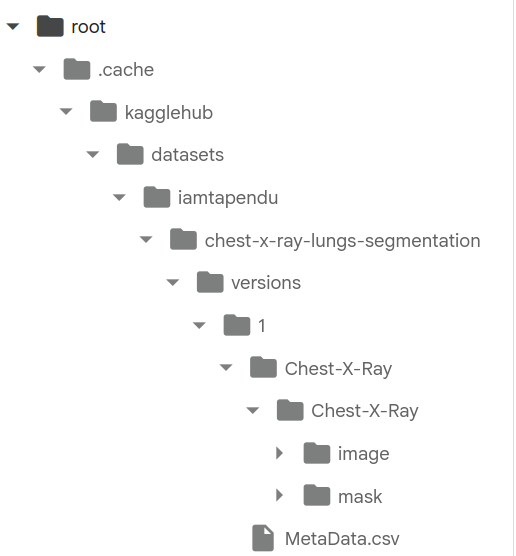

## SET UP OF THE DATABASE

In [32]:
import os
import shutil

sets = ['train', 'test', 'val']

for st in sets:
  shutil.rmtree(os.path.join(os.getcwd(), st))

shutil.rmtree(os.path.join(os.getcwd(), 'ROI_Images'))

,id,gender,age,county,ptb,remarks
0,1000,male,31,Shenxhen,0,normal
1,1001,male,64,Shenxhen,0,normal
2,1002,male,35,Shenxhen,0,normal
3,1003,male,32,Shenxhen,1,"STB,ATB,tuberculosis pleuritis"
4,1004,male,2,Shenxhen,1,secondary PTB in the bilateral upper field



# of TB images: 345
# of Normal images: 359
Total: 704
Successfuly created Images Directory


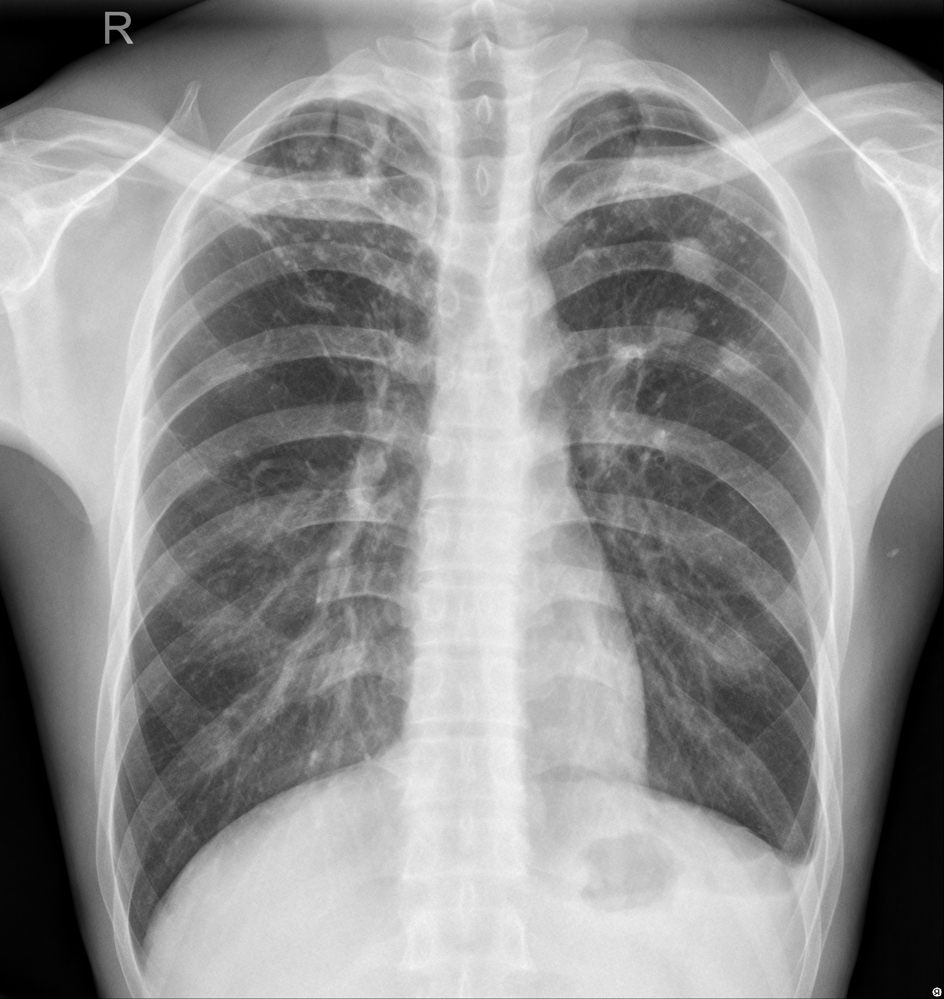

In [14]:
def create_images_folder(path):

  ''' Argument is the path to the folder the xrays have been downloaded
  Creates an image directory filled with images, and a roi_images directory
  that is empty.
  Returns images list from TB and NO-TB Classes.'''

  import os
  import pandas as pd

  # load the metadata
  metadata = pd.read_csv(os.path.join(path, 'MetaData.csv'))
  display (metadata.head())

  # Get the ids of the images corr to TB and no-TB
  img_id1 = list (metadata['id'][metadata['ptb'] == 1])
  img_id0 = list(metadata['id'][metadata['ptb'] == 0])

  print()
  print(f'# of TB images: {len(img_id1)}')
  print(f'# of Normal images: {len(img_id0)}')
  print(f'Total: {len(img_id1) + len(img_id0)}')

  ## set up image and roi_images directory

  import os
  import shutil

  sets = ['Images',
          ]
  klases = ['tb', 'no_tb']

  # get current directory
  current_path = os.getcwd()

  for st in sets:
    for klas in klases:
        if not os.path.exists(os.path.join(current_path, st, klas)):
          os.makedirs(os.path.join(current_path, st, klas))

  # path to the images
  path_images = os.path.join(path, 'Chest-X-Ray/Chest-X-Ray/image')

  # copying from the image path to set up directories

  # TB Images
  for i in img_id1:
    str_i = str(i) + '.png' #convert id into image id string
    shutil.copy(src = os.path.join(path_images,str_i), dst = os.path.join(current_path,'Images', 'tb'))

  # No TB Images
  for i in img_id0:
    str_i = str(i) + '.png' #convert id into image id string
    shutil.copy(src = os.path.join(path_images,str_i), dst = os.path.join(current_path,'Images','no_tb'))

  print (f'Successfuly created Images Directory')

  return img_id1, img_id0

# create
img_id1, img_id0 = create_images_folder(path)

# show sample image

import PIL

path_image = './Images/tb/1003.png'
PIL.Image.open(path_image)

### Load model for segmentation

In [33]:
from torchvision.models import vgg16_bn
import torch.nn as nn


# CONV AND UP_CONV LAYERS
def conv(in_channels, out_channels):
  return nn.Sequential(
      nn.Conv2d(in_channels, out_channels, kernel_size = 3, stride=1, padding = 1),
      nn.BatchNorm2d(out_channels),
      nn.ReLU(inplace=True)
  )

def up_conv(in_channels, out_channels):
  return nn.Sequential(
      nn.ConvTranspose2d(in_channels, out_channels, kernel_size = 2, stride = 2),
      nn.BatchNorm2d(out_channels),
      nn.ReLU(inplace=True)
  )


# UNET CLASS
class UNet(nn.Module):

  def __init__(self, num_classes = 2):
    super().__init__()

    self.encoder = vgg16_bn(weights = 'DEFAULT').features

    self.block1 = nn.Sequential(*self.encoder[:6])
    self.block2 = nn.Sequential(*self.encoder[6:13])
    self.block3 = nn.Sequential(*self.encoder[13:20])
    self.block4 = nn.Sequential(*self.encoder[20:27])
    self.block5 = nn.Sequential(*self.encoder[27:34])

    self.bottleneck = nn.Sequential(*self.encoder[34:])
    self.conv_bottleneck = conv(512, 1024) #increase channels. prepare for upsampling

    self.up_conv6 = up_conv(1024, 512)
    self.conv6 = conv(512 + 512, 512)
    self.up_conv7 = up_conv(512, 256)
    self.conv7 = conv(256 + 512, 256)
    self.up_conv8 = up_conv(256, 128)
    self.conv8 = conv(128 + 256, 128)
    self.up_conv9 = up_conv(128, 64)
    self.conv9 = conv(64 + 128, 64)
    self.up_conv10 = up_conv(64, 32)
    self.conv10 = conv(32 + 64, 32)

    self.conv11 = nn.Conv2d(32, num_classes, kernel_size = 1)

  def forward(self, x):

    # input is (3, 224, 224)
    # output is (64, 224, 224)
    block1 = self.block1(x)

    #output is (128, 112, 112)
    block2 = self.block2(block1)

    #output (256, 56, 56)
    block3 = self.block3(block2)

    #output (512, 28, 28)
    block4 = self.block4(block3)

    #output (512, 14, 14)
    block5 = self.block5(block4)

    #output (512, 7, 7)
    bottleneck = self.bottleneck(block5)

    #ouput (1024, 7, 7)
    x = self.conv_bottleneck(bottleneck)

    # output is (512, 14, 14)
    x = self.up_conv6(x)
    # output (512 + 512, 14, 14)
    x = torch.cat([x, block5], dim = 1) # we concatenate along the channels (i.e stack the features)
    # output is (512, 14, 14)
    x = self.conv6(x)

    # output (256, 28, 28)
    x = self.up_conv7(x)

    # output (256 + 512, 28, 28)
    x = torch.cat([x, block4], dim = 1)
    # output (256, 28, 28)
    x = self.conv7(x)

    # output (128, 56, 56)
    x = self.up_conv8(x)
    # output (128 + 256, 56, 56)
    x = torch.cat([x, block3], dim = 1)
    # output (128, 56, 56)
    x = self.conv8(x)

    # output (64, 112, 112)
    x = self.up_conv9(x)
    # output (64 + 128, 112, 112)
    x = torch.cat([x, block2], dim = 1)
    # output (64, 112, 112)
    x = self.conv9(x)

    # output (64, 224, 224)
    x = self.up_conv10(x)
    # output (64 + 64, 224, 224)
    x = torch.cat([x, block1], dim = 1)
    # output (32, 224, 224)
    x = self.conv10(x)

    # output (n_classes, 224, 224)
    x = self.conv11(x)

    return x

import os
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model_path = os.path.join(path_segmentation, 'seg_unet_2.pth')
model = UNet()

model.load_state_dict(torch.load(model_path, map_location = device))

model.to(device)

UNet(
  (encoder): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(128, 256

### Prepare Data

Number of batches: 11
Number of Images: 704


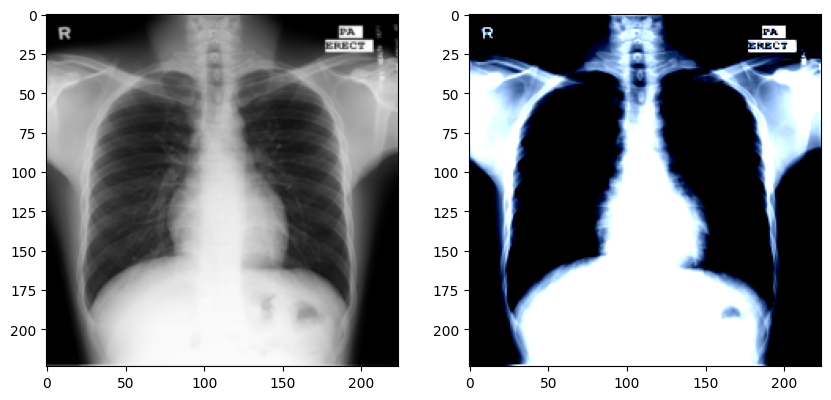

In [34]:
import torch
from torch.utils.data import Dataset
from torchvision.transforms import v2 as T
import os
import PIL


class ROI(Dataset):

  ''' Returns an tensor object that can be batched for segmentation inference'''

  def __init__(self, root_dir):

    # transforms used in the segmentation model for eval, not training

    self.transforms_norm = T.Compose([
        T.Resize((224, 224)),
        T.ToImage(), #converts a PIL Image to tv2_tensor
        T.ToDtype(torch.float32, scale = True), # scales
        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])

    self.transforms_orig = T.Compose([
        T.Resize((224, 224)),
        T.ToImage(), #converts a PIL Image to tv2_tensor
        T.ToDtype(torch.float32, scale = True),
    ])

    # directory with Images
    self.root_dir = root_dir

    # sub-directories
    im_id0 = os.listdir (os.path.join(self.root_dir, 'no_tb'))
    im_id1 = os.listdir (os.path.join(self.root_dir, 'tb'))

    # add a tag of 0 and 1 for labelling later
    # im_id0_tag = ['0_' + im for im in im_id0]
    # im_id1_tag = ['1_' + im for im in im_id1]

    # a full list with tagged image names
    # self.im_ls = im_id0_tag + im_id1_tag

    # GEMINI clean GENIUS
    self.im_data = []

    for f in im_id0:
      self.im_data.append(('no_tb', f, 0))

    for f in im_id1:
      self.im_data.append(('tb', f, 1))

  def __len__(self):
    return len(self.im_data)


  def __getitem__(self, idx):

    # if self.im_ls[idx].startswith('0_'):
    #   label = torch.tensor(0).long()
    # else:
    #   label = torch.tensor(1).long()

    # we start from index 2 since that is where the actual image name is found.
    # im_path = os.path.join(self.root_dir, self.im_ls[idx][2:])

    im_path = os.path.join(self.root_dir, self.im_data[idx][0], self.im_data[idx][1])
    label = torch.tensor(self.im_data[idx][2]).long()

    # get the name. will be useful for saving in the inference loop
    im_name = self.im_data[idx][1]


    image = PIL.Image.open(im_path).convert('RGB')

    image_orig = self.transforms_orig(image)

    image_norm = self.transforms_norm(image)

    return image_orig, image_norm, label, im_name

# tensor dataset
td = ROI('./Images')

# confirm images display
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize = (10, 10))

ax[0].imshow(td[0][0].permute(1, 2, 0))
ax[1].imshow(td[0][1].permute(1, 2, 0))

# data loader
dl = DataLoader (td, batch_size = 64)

# Number of batches and images
print (f'Number of batches: {len(dl)}')

# Number of images
print (f'Number of Images: {len(dl.dataset)}')

### Inference 1

alpha = 0

In [17]:
from torchvision.utils import save_image
import os
import torch

def segmentation_inference (model, data_loader, device, roi_dir):

  model.to(device)
  model.eval()

  all_roi = []

  # make directories if non_existent

  os.makedirs (os.path.join(roi_dir, 'tb'), exist_ok=True)
  os.makedirs (os.path.join(roi_dir, 'no_tb'), exist_ok=True)

  print(f"Starting inference. Saving images to {roi_dir}...")

  with torch.no_grad():
    for batch_idx, batch in enumerate(data_loader):

      images_orig = batch[0].to(device)
      images_norm = batch[1].to(device)

      label_batch = batch[2] # no need to be in device
      img_name_batch = batch[3]

      # predicted masks
      masks = model(images_norm)
      pred_masks = masks.argmax(dim = 1)

      # roi
      # roi_images = images_orig[:, 1, :, :] * pred_masks.unsqueeze(1)
      roi_batch = images_orig * pred_masks.unsqueeze(1) # i did not know broadcasting is allowed for such an instance where there is a channel mismatch

      # loop over the batch of roi images generated to save
      for i in range(len(roi_batch)):

        img = roi_batch[i]
        img_name = img_name_batch[i]

        folder = 'tb' if label_batch[i] == 1 else 'no_tb'

        save_image(img, os.path.join(roi_dir, folder, img_name), normalize = True)

      if (batch_idx+1)%5 == 0:
        print (f'Finished saving {batch_idx+1} batches.')

# segment
segmentation_inference (model, dl, device, './ROI_Images')

Starting inference. Saving images to ./ROI_Images...
Finished saving 5 batches.
Finished saving 10 batches.


### Inference 2

alpha = 0.4

In [35]:
from torchvision.utils import save_image
import os
import torch
import time  # Import time module

def segmentation_inference(model, data_loader, device, roi_dir):

  model.to(device)
  model.eval()

  # make directories if non_existent
  os.makedirs(os.path.join(roi_dir, 'tb'), exist_ok=True)
  os.makedirs(os.path.join(roi_dir, 'no_tb'), exist_ok=True)

  print(f"Starting inference. Saving images to {roi_dir}...")

  # --- TIMER START ---
  start_time = time.time()

  # Counter to track total images for precise per-image timing
  total_images = 0

  with torch.no_grad():
    for batch_idx, batch in enumerate(data_loader):

      images_orig = batch[0].to(device)
      images_norm = batch[1].to(device)

      label_batch = batch[2] # no need to be in device
      img_name_batch = batch[3]

      # Update count
      total_images += len(images_orig)

      # predicted masks
      masks = model(images_norm)
      pred_masks = masks.argmax(dim=1)

      # roi
      # Broadcasting works here because PyTorch aligns the dimensions from the right.
      # images_orig is [B, 3, H, W] and pred_masks.unsqueeze(1) is [B, 1, H, W].
      # roi_batch = images_orig * pred_masks.unsqueeze(1)

            # CHANGE
      alpha = 0.4  # background intensity factor

      mask = pred_masks.unsqueeze(1).float()
      roi_batch = images_orig * (mask + alpha * (1 - mask))

      # loop over the batch of roi images generated to save
      for i in range(len(roi_batch)):

        img = roi_batch[i]
        img_name = img_name_batch[i]

        folder = 'tb' if label_batch[i] == 1 else 'no_tb'

        # Note: I removed normalize=True here usually because 'img' is likely already
        # in the correct pixel range from 'images_orig'.
        # If 'images_orig' was 0-255, normalize=True might distort it.
        # If it was 0-1, it's fine. keeping it as you had it.
        save_image(img, os.path.join(roi_dir, folder, img_name), normalize=True)

      if (batch_idx+1) % 5 == 0:
        print(f'Finished saving {batch_idx+1} batches.')

  # --- TIMER END ---
  end_time = time.time()
  total_time = end_time - start_time

  # Display stats
  print("-" * 30)
  print(f"Inference Completed.")
  print(f"Total Time:      {total_time/60:.2f} minutes")

  if total_images > 0:
      print(f"Time per Image:  {total_time / total_images:.4f} seconds")
      print(f"FPS:             {total_images / total_time:.2f}")

# segment
segmentation_inference(model, dl, device, './ROI_Images')

Starting inference. Saving images to ./ROI_Images...
Finished saving 5 batches.
Finished saving 10 batches.
------------------------------
Inference Completed.
Total Time:      3.27 minutes
Time per Image:  0.2788 seconds
FPS:             3.59


### Check ROI Image

### run 1

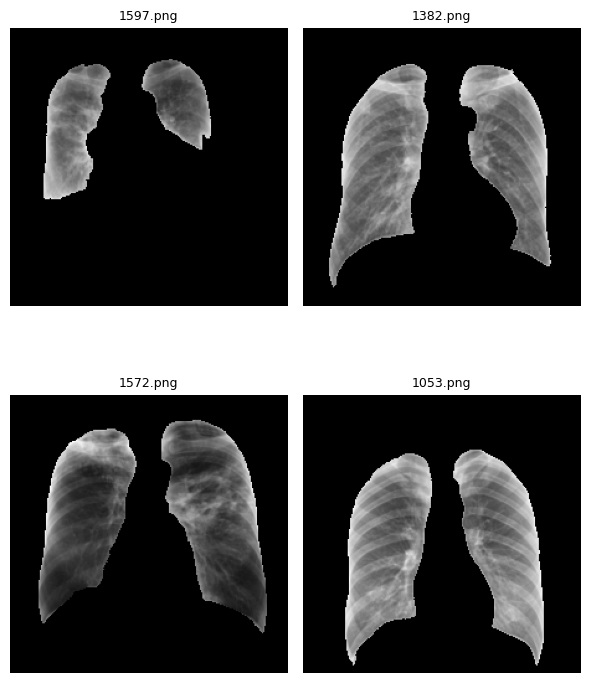

In [18]:
# claude generated

import os
import PIL
import matplotlib.pyplot as plt

# Get a list of images in the 'tb' subfolder of ROI_Images
roi_tb_images = os.listdir('./ROI_Images/tb')

if len(roi_tb_images) >= 4:
    fig, axes = plt.subplots(2, 2, figsize=(6, 8))

    for i, ax in enumerate(axes.flatten()):
        img_path = os.path.join('./ROI_Images/tb', roi_tb_images[i])
        ax.imshow(PIL.Image.open(img_path), cmap='gray')
        ax.set_title(f"{roi_tb_images[i]}", fontsize=9)
        ax.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print(f"Not enough images found. Only {len(roi_tb_images)} available.")

### run 2

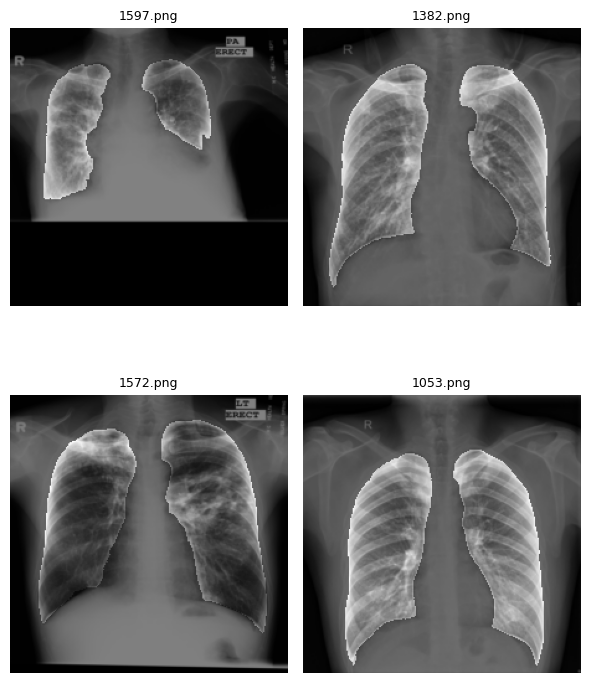

In [36]:
# claude generated

import os
import PIL
import matplotlib.pyplot as plt

# Get a list of images in the 'tb' subfolder of ROI_Images
roi_tb_images = os.listdir('./ROI_Images/tb')

if len(roi_tb_images) >= 4:
    fig, axes = plt.subplots(2, 2, figsize=(6, 8))

    for i, ax in enumerate(axes.flatten()):
        img_path = os.path.join('./ROI_Images/tb', roi_tb_images[i])
        ax.imshow(PIL.Image.open(img_path), cmap='gray')
        ax.set_title(f"{roi_tb_images[i]}", fontsize=9)
        ax.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print(f"Not enough images found. Only {len(roi_tb_images)} available.")

# CLASSIFICATION SEG DATA 704

#### Notes for section:

__On exploration of metadata__

- Looks like we have 704 images, the id column of the metadata should have a correspondence with the naming of the images (not confirmed, but more likely)

- Every image seems to have its segmentation masks, since we have 704 segmentation masks.

- The age column is pretty messed up. We have a combination of strings integers and texts with integers. The gender column is also pretty messed up.

- The distribution of positive and negative classes is balanced.

## SET UP OF THE DATABASE

In [37]:
def setup_roi_database(path):

  '''Set up of the ROI Images database to use for classification. The target is
  to just use ImageFolder for the tensor dataset and data loader.

  path is the folder where the images are''' #there was sth causing syntax warning

  import os
  import pandas as pd

  roi_0 = os.listdir(os.path.join(path, 'no_tb'))
  roi_1 = os.listdir(os.path.join(path, 'tb'))

  print('Splitting Details')
  print(f'# of TB images: {len(roi_1)}')
  print(f'# of Normal images: {len(roi_0)}')
  print(f'Total: {len(roi_1) + len(roi_0)}')

  # We will split train, validation and test set using 70%, 20% and 10%.
  # We will consider these ratios at the class level since we want every set
  # have a balanced number of images wrt the classes.

  train_ratio = 0.7
  val_ratio = 0.2
  test_ratio = 0.1

  # int uses floor, so the test set will have a couple more images than intended
  train_no_1 = int(train_ratio * len(roi_1))
  train_no_0 = int(train_ratio * len(roi_0))
  # print(f'Train: {train_no_1} + {train_no_0} = {train_no_1 + train_no_0}')

  val_no_1 = int(val_ratio * len(roi_1))
  val_no_0 = int(val_ratio * len(roi_0))
  # print(f'Validation: {val_no_1} + {val_no_0} = {val_no_1 + val_no_0}')

  test_no_1 = int(test_ratio * len(roi_1))
  test_no_0 = int(test_ratio * len(roi_0))
  # print(f'Test: {test_no_1} + {test_no_0} = {test_no_1 + test_no_0}')

  # split
  train_1 = roi_1[:train_no_1]
  train_0 = roi_0[:train_no_0]
  train = train_1 + train_0
  print(f'Train set #: {len(train)}')

  val_1 = roi_1[train_no_1:train_no_1 + val_no_1]
  val_0 = roi_0[train_no_0:train_no_0 + val_no_0]
  val = val_1 + val_0
  print(f'Validation set #: {len(val)}')

  test_1 = roi_1[train_no_1 + val_no_1:]
  test_0 = roi_0[train_no_0 + val_no_0:]
  test = test_1 + test_0
  print(f'Test set #: {len(test)}')

  print(f'Total: {len(train) + len(val) + len(test)}')
  print()


  ## set up directories

  print ('Setting up directories..')
  import os
  import shutil

  sets = ['train', 'val', 'test']
  klases = ['tb', 'no_tb']

  current_path = os.getcwd()

  for s in sets:
    for klas in klases:
      os.makedirs(os.path.join(current_path, s, klas), exist_ok = True)

  # copying from the image path to set up directories. code is really repetitive and bad, but it works!

  #train
  for i in train_1:
    shutil.copy(src = os.path.join(path,'tb', i), dst = os.path.join(current_path,'train','tb'))

  for i in train_0:
    shutil.copy(src = os.path.join(path,'no_tb', i), dst = os.path.join(current_path,'train','no_tb'))

  # val
  for i in val_1:
    shutil.copy(src = os.path.join(path,'tb', i), dst = os.path.join(current_path,'val','tb'))

  for i in val_0:
    shutil.copy(src = os.path.join(path,'no_tb', i), dst = os.path.join(current_path,'val','no_tb'))

  #test
  for i in test_1:
    shutil.copy(src = os.path.join(path,'tb', i), dst = os.path.join(current_path,'test','tb'))

  for i in test_0:
    shutil.copy(src = os.path.join(path,'no_tb', i), dst = os.path.join(current_path,'test','no_tb'))

setup_roi_database('./ROI_Images')

Splitting Details
# of TB images: 345
# of Normal images: 359
Total: 704
Train set #: 492
Validation set #: 140
Test set #: 72
Total: 704

Setting up directories..


### Computing masks mean and std for normalization (HA)

In [20]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. Compute mean and std from the training set
# ------------------------------------------------------------
# We'll use a simple transform without augmentation (only resize + to tensor)
basic_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

# Create a temporary dataset to compute statistics
temp_train_ds = ImageFolder(root='./train', transform=basic_transform)

# Function to compute mean and std
def compute_mean_std(dataset, batch_size=64, num_workers=2):
    loader = DataLoader(dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)

    mean = 0.0
    std = 0.0
    total_pixels = 0

    for images, _ in loader:
        # images shape: (batch, channels, height, width)
        batch_samples = images.size(0)
        images = images.view(batch_samples, images.size(1), -1)  # flatten spatial dims
        # accumulate mean per channel
        mean += images.mean(2).sum(0)
        total_pixels += batch_samples

    mean /= total_pixels

    # second pass for std
    for images, _ in loader:
        batch_samples = images.size(0)
        images = images.view(batch_samples, images.size(1), -1)
        var = ((images - mean.view(1, -1, 1)) ** 2).mean(2).sum(0)
        std += var

    std = torch.sqrt(std / total_pixels)

    return mean, std

print("Computing mean and std from training set...")
mean, std = compute_mean_std(temp_train_ds)
print(f"Mean: {mean}")   # e.g., tensor([0.485, 0.456, 0.406]) if RGB, but for grayscale they will be nearly identical
print(f"Std:  {std}")

Computing mean and std from training set...
Mean: tensor([0.1378, 0.1378, 0.1378])
Std:  tensor([0.2578, 0.2578, 0.2578])


### run 1_0a (HA + no aug)

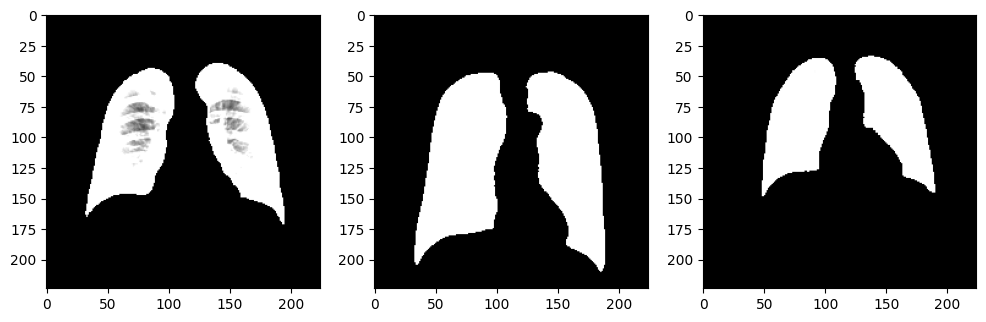

In [21]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt
import numpy as np

# for any randomization
torch.manual_seed(7)

## DATASET

transforms = T.Compose([
    # T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean = mean, std = std)
])

train_td = ImageFolder(root = './train', transform = transforms)
val_td = ImageFolder(root = './val', transform = transforms)
test_td = ImageFolder(root = './test', transform = transforms)

train_dl = DataLoader(train_td, batch_size = 32, shuffle = True)
val_dl = DataLoader(val_td, batch_size = 32)
test_dl = DataLoader(test_td, batch_size = 32)

# PLot the images in the sets to see if transformation was successfull.
fig, ax = plt.subplots(1, 3, figsize = (12, 8))

ax[0].imshow(train_td[0][0].permute(1, 2, 0));

ax[1].imshow(test_td[0][0].permute(1, 2, 0));

ax[2].imshow(val_td[0][0].permute(1, 2, 0));

Best model saved at epoch 1
Epoch: [1/50]	 Train Loss: 0.76	    Val Loss: 0.69	 Train Acc: 0.55	 Val Acc: 0.51    Train Time: 0.05	 Val Time: 0.01
Best model saved at epoch 2
Epoch: [2/50]	 Train Loss: 0.66	    Val Loss: 0.67	 Train Acc: 0.58	 Val Acc: 0.61    Train Time: 0.05	 Val Time: 0.01
Epoch: [3/50]	 Train Loss: 0.65	    Val Loss: 0.68	 Train Acc: 0.60	 Val Acc: 0.56    Train Time: 0.05	 Val Time: 0.01
Best model saved at epoch 4
Epoch: [4/50]	 Train Loss: 0.66	    Val Loss: 0.65	 Train Acc: 0.59	 Val Acc: 0.73    Train Time: 0.05	 Val Time: 0.01
Best model saved at epoch 5
Epoch: [5/50]	 Train Loss: 0.61	    Val Loss: 0.65	 Train Acc: 0.64	 Val Acc: 0.65    Train Time: 0.05	 Val Time: 0.01
Best model saved at epoch 6
Epoch: [6/50]	 Train Loss: 0.60	    Val Loss: 0.64	 Train Acc: 0.68	 Val Acc: 0.66    Train Time: 0.05	 Val Time: 0.01
Epoch: [7/50]	 Train Loss: 0.59	    Val Loss: 0.65	 Train Acc: 0.65	 Val Acc: 0.66    Train Time: 0.05	 Val Time: 0.01
Best model saved at epoch 8

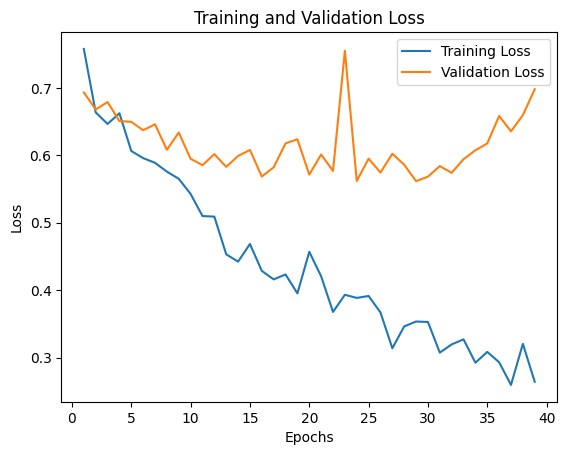

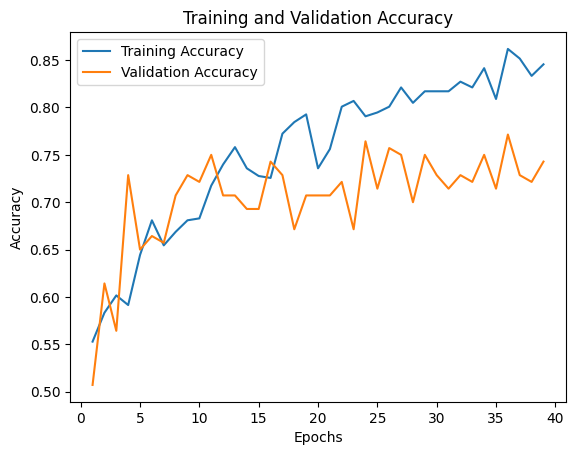

Training time : 1.87
Validation time : 0.32


In [22]:
# MODEL

class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()


# TRAINING

# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001, betas = (0.9, 0.99))

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
save_path = os.path.join(path_classification, 'custom_class_seg_noaug_ha.pt')

history_train = model_train_save_es(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 50, patience = 10, device = device
)

#plot
plot_results_new(history_train)

# total time taken for training and validation
print(f"Training time : {sum(history_train['Training']['Time']):.2f}")
print(f"Validation time : {sum(history_train['Validation']['Time']):.2f}")

#### Load and Predict

Prediction Metrics
Test Accuracy: 0.7222 | f1: 0.7297 | AUC: 0.7707
Sensitivity: 0.7714 | Specificity: 0.6757
Precision: 0.6923| Test Time: 0.0039


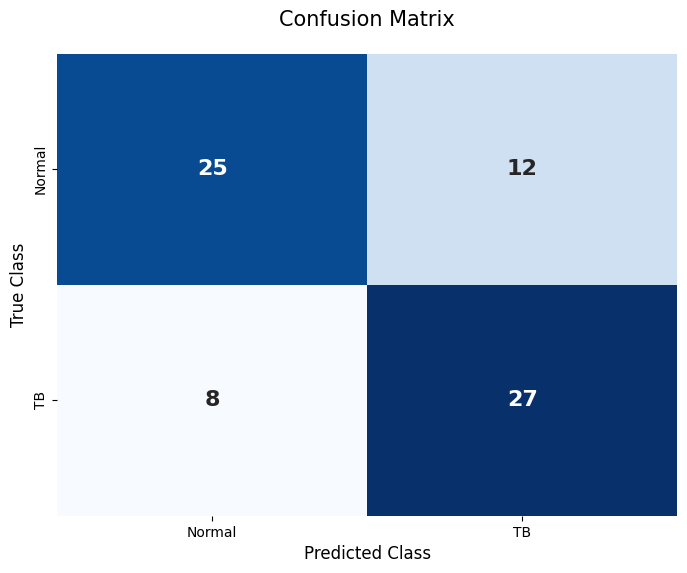

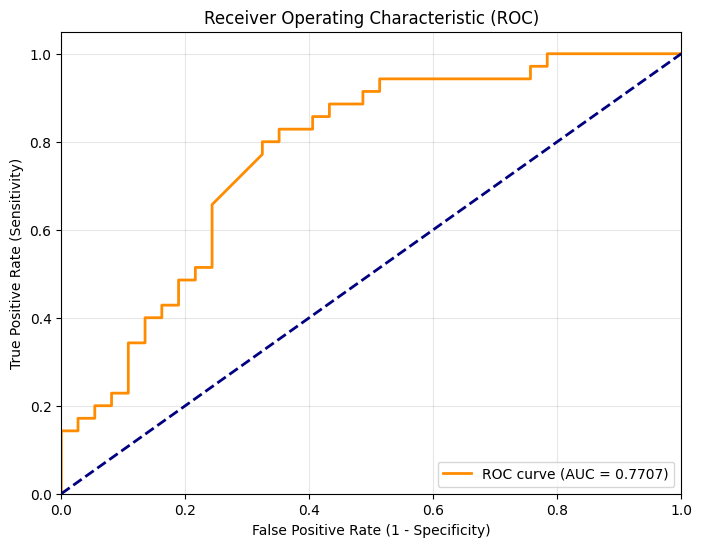

In [23]:
## DATASET

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

transforms = T.Compose([
    # T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean = mean, std = std)
])

test_td = ImageFolder(root = './test', transform = transforms)
test_dl = DataLoader(test_td, batch_size = 32)

path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
PATH = os.path.join(path_classification, 'custom_class_seg_noaug_ha.pt')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = torch.load(PATH, map_location = device, weights_only=False)

predictions, probs, labels = model_predict_new(model, test_dl, device)

### run 1_0 (HA + aug)

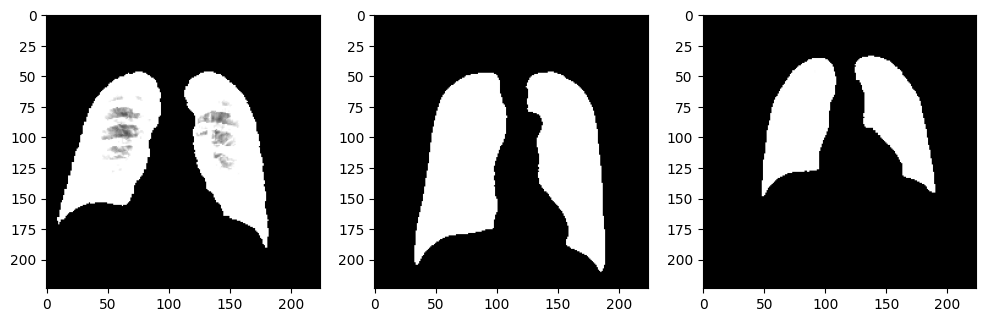

In [30]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt
import numpy as np

# TRANSFORMS

transforms = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)      # <--- normalization added
])

# TENSOR DATASETS
train_td = ImageFolder(root = './train', transform = T.Compose([
    T.RandomHorizontalFlip(p = 0.5),
    T.RandomAffine(degrees = 10, #patient is not always straight
                       translate = (0.1, 0.1), #shift it vertically and horizontally from the center
                       scale = (0.9, 1.1)), # controls the size of the lungs
    T.ColorJitter(brightness = 0.1, contrast = 0.1),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)      # <--- normalization added
])
)

val_td = ImageFolder(root = './val', transform = transforms)
test_td = ImageFolder(root = './test', transform = transforms)

# TO BATCHES
train_dl = DataLoader(train_td, batch_size = 32, shuffle = True)
val_dl = DataLoader(val_td, batch_size = 32)
test_dl = DataLoader(test_td, batch_size = 32)

# PLot the images in the sets to see if transformation was successfull.
fig, ax = plt.subplots(1, 3, figsize = (12, 8))

ax[0].imshow(train_td[0][0].permute(1, 2, 0));

ax[1].imshow(test_td[0][0].permute(1, 2, 0));

ax[2].imshow(val_td[0][0].permute(1, 2, 0));

Best model saved at epoch 1
Epoch: [1/50]	 Train Loss: 0.75	    Val Loss: 0.72	 Train Acc: 0.48	 Val Acc: 0.51    Train Time: 0.06	 Val Time: 0.01
Best model saved at epoch 2
Epoch: [2/50]	 Train Loss: 0.70	    Val Loss: 0.72	 Train Acc: 0.51	 Val Acc: 0.51    Train Time: 0.06	 Val Time: 0.01
Best model saved at epoch 3
Epoch: [3/50]	 Train Loss: 0.70	    Val Loss: 0.71	 Train Acc: 0.51	 Val Acc: 0.51    Train Time: 0.07	 Val Time: 0.01
Best model saved at epoch 4
Epoch: [4/50]	 Train Loss: 0.70	    Val Loss: 0.71	 Train Acc: 0.51	 Val Acc: 0.51    Train Time: 0.06	 Val Time: 0.01
Best model saved at epoch 5
Epoch: [5/50]	 Train Loss: 0.70	    Val Loss: 0.71	 Train Acc: 0.51	 Val Acc: 0.51    Train Time: 0.06	 Val Time: 0.01
Best model saved at epoch 6
Epoch: [6/50]	 Train Loss: 0.70	    Val Loss: 0.71	 Train Acc: 0.51	 Val Acc: 0.51    Train Time: 0.06	 Val Time: 0.01
Best model saved at epoch 7
Epoch: [7/50]	 Train Loss: 0.70	    Val Loss: 0.71	 Train Acc: 0.51	 Val Acc: 0.51    Trai

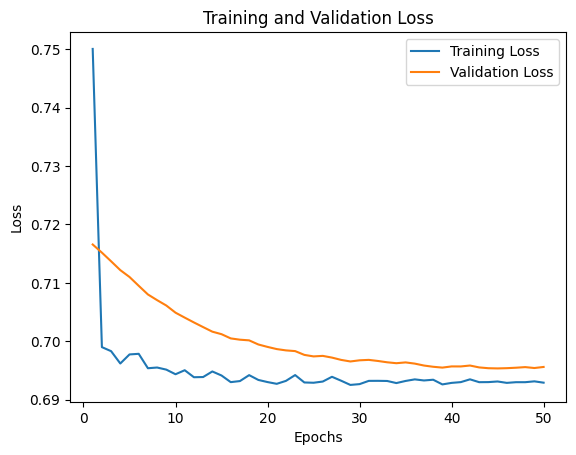

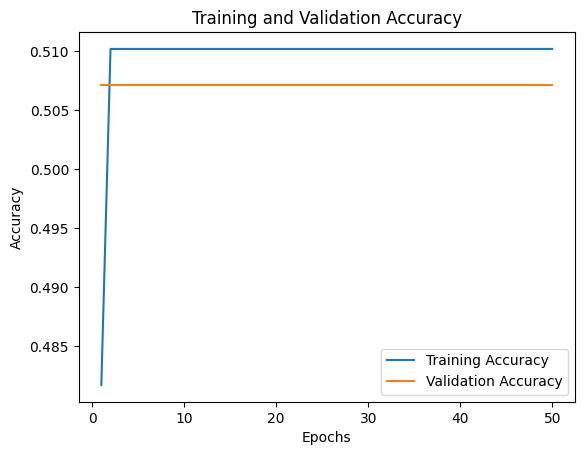

Training time : 3.16
Validation time : 0.41


In [31]:
# MODEL

class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()


# TRAINING

# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001, betas = (0.9, 0.99))

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
save_path = os.path.join(path_classification, 'custom_class_seg_aug_ha.pt')

history_train = model_train_save_es(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 50, patience = 10, device = device
)

#plot
plot_results_new(history_train)

# total time taken for training and validation
print(f"Training time : {sum(history_train['Training']['Time']):.2f}")
print(f"Validation time : {sum(history_train['Validation']['Time']):.2f}")

#### Load and Predict

Prediction Metrics
Test Accuracy: 0.4861 | f1: 0.6542 | AUC: 0.7158
Sensitivity: 1.0000 | Specificity: 0.0000
Precision: 0.4861| Test Time: 0.0039


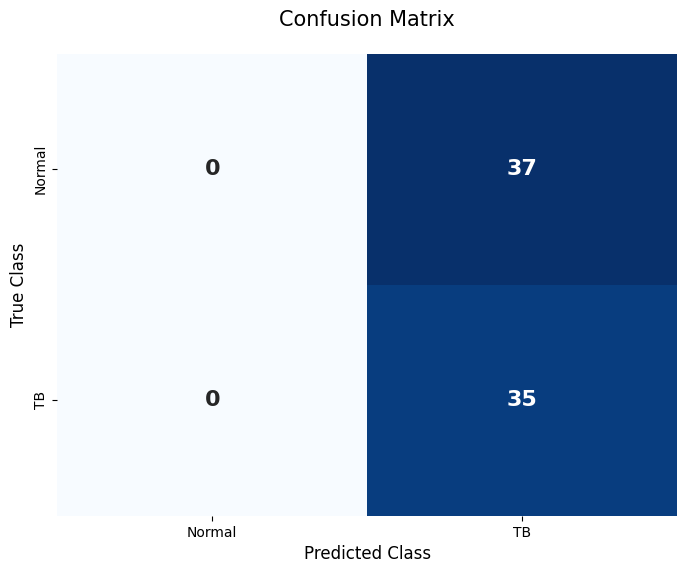

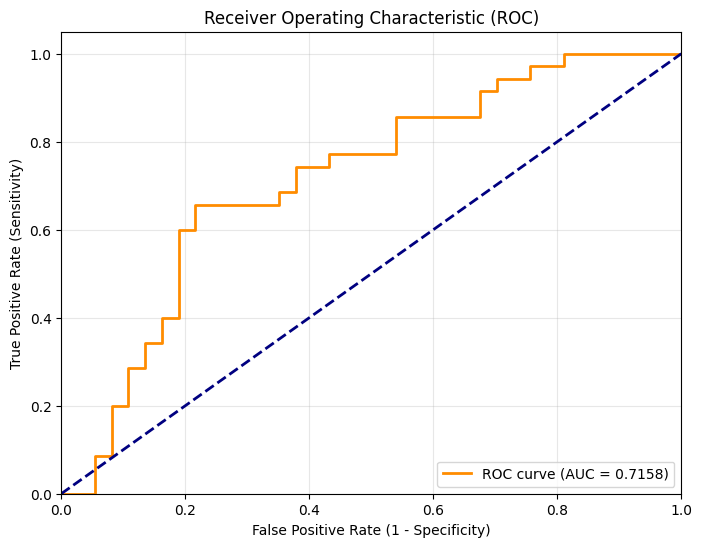

In [26]:
## DATASET

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

transforms = T.Compose([
    T.ToTensor(),
    T.Normalize(mean = mean, std = std)
])

test_td = ImageFolder(root = './test', transform = transforms)
test_dl = DataLoader(test_td, batch_size = 32)

path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
PATH = os.path.join(path_classification, 'custom_class_seg_aug_ha.pt')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = torch.load(PATH, map_location = device, weights_only=False)

predictions, probs, labels = model_predict_new(model, test_dl, device)

### Computing masks mean and std for normalization (SA)

In [38]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. Compute mean and std from the training set
# ------------------------------------------------------------
# We'll use a simple transform without augmentation (only resize + to tensor)
basic_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

# Create a temporary dataset to compute statistics
temp_train_ds = ImageFolder(root='./train', transform=basic_transform)

# Function to compute mean and std
def compute_mean_std(dataset, batch_size=64, num_workers=2):
    loader = DataLoader(dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)

    mean = 0.0
    std = 0.0
    total_pixels = 0

    for images, _ in loader:
        # images shape: (batch, channels, height, width)
        batch_samples = images.size(0)
        images = images.view(batch_samples, images.size(1), -1)  # flatten spatial dims
        # accumulate mean per channel
        mean += images.mean(2).sum(0)
        total_pixels += batch_samples

    mean /= total_pixels

    # second pass for std
    for images, _ in loader:
        batch_samples = images.size(0)
        images = images.view(batch_samples, images.size(1), -1)
        var = ((images - mean.view(1, -1, 1)) ** 2).mean(2).sum(0)
        std += var

    std = torch.sqrt(std / total_pixels)

    return mean, std

print("Computing mean and std from training set...")
mean, std = compute_mean_std(temp_train_ds)
print(f"Mean: {mean}")   # e.g., tensor([0.485, 0.456, 0.406]) if RGB, but for grayscale they will be nearly identical
print(f"Std:  {std}")

Computing mean and std from training set...
Mean: tensor([0.3442, 0.3442, 0.3442])
Std:  tensor([0.1947, 0.1947, 0.1947])


### run 2_0a (SA + no aug)

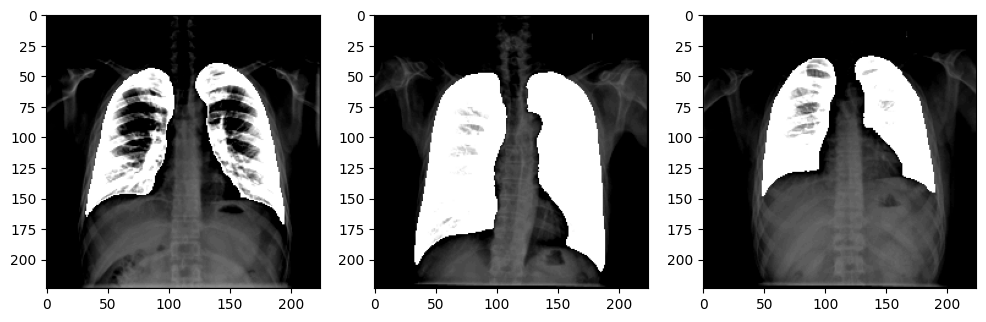

In [45]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt
import numpy as np

# for any randomization
torch.manual_seed(7)

## DATASET

transforms = T.Compose([
    # T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean = mean, std = std)
])

train_td = ImageFolder(root = './train', transform = transforms)
val_td = ImageFolder(root = './val', transform = transforms)
test_td = ImageFolder(root = './test', transform = transforms)

train_dl = DataLoader(train_td, batch_size = 32, shuffle = True)
val_dl = DataLoader(val_td, batch_size = 32)
test_dl = DataLoader(test_td, batch_size = 32)

# PLot the images in the sets to see if transformation was successfull.
fig, ax = plt.subplots(1, 3, figsize = (12, 8))

ax[0].imshow(train_td[0][0].permute(1, 2, 0));

ax[1].imshow(test_td[0][0].permute(1, 2, 0));

ax[2].imshow(val_td[0][0].permute(1, 2, 0));

Best model saved at epoch 1
Epoch: [1/50]	 Train Loss: 0.73	    Val Loss: 0.69	 Train Acc: 0.54	 Val Acc: 0.51    Train Time: 0.06	 Val Time: 0.01
Best model saved at epoch 2
Epoch: [2/50]	 Train Loss: 0.67	    Val Loss: 0.65	 Train Acc: 0.51	 Val Acc: 0.51    Train Time: 0.05	 Val Time: 0.01
Epoch: [3/50]	 Train Loss: 0.67	    Val Loss: 0.67	 Train Acc: 0.51	 Val Acc: 0.51    Train Time: 0.05	 Val Time: 0.01
Epoch: [4/50]	 Train Loss: 0.66	    Val Loss: 0.68	 Train Acc: 0.60	 Val Acc: 0.69    Train Time: 0.06	 Val Time: 0.01
Epoch: [5/50]	 Train Loss: 0.64	    Val Loss: 0.68	 Train Acc: 0.66	 Val Acc: 0.62    Train Time: 0.06	 Val Time: 0.01
Epoch: [6/50]	 Train Loss: 0.64	    Val Loss: 0.68	 Train Acc: 0.68	 Val Acc: 0.69    Train Time: 0.05	 Val Time: 0.01
Epoch: [7/50]	 Train Loss: 0.62	    Val Loss: 0.70	 Train Acc: 0.69	 Val Acc: 0.56    Train Time: 0.05	 Val Time: 0.01
Best model saved at epoch 8
Epoch: [8/50]	 Train Loss: 0.62	    Val Loss: 0.65	 Train Acc: 0.69	 Val Acc: 0.74 

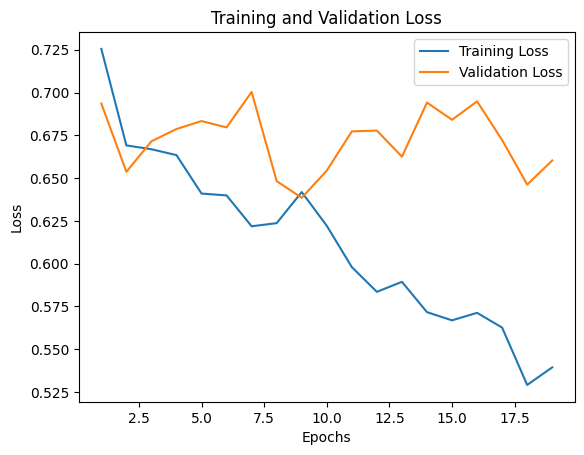

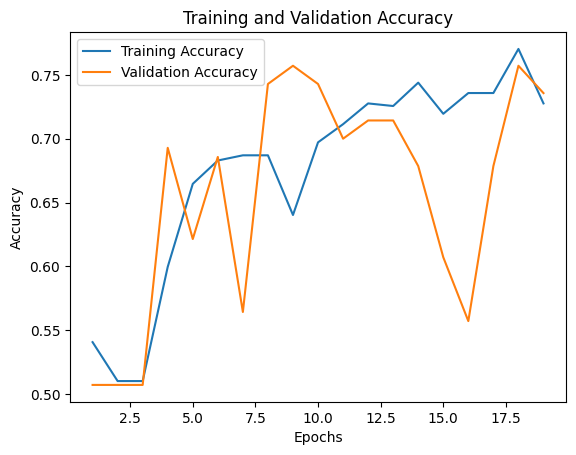

Training time : 1.01
Validation time : 0.18


In [46]:
# MODEL

class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()


# TRAINING

# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001, betas = (0.9, 0.99))

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
save_path = os.path.join(path_classification, 'custom_class_seg_noaug_sa.pt')

history_train = model_train_save_es(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 50, patience = 10, device = device
)

#plot
plot_results_new(history_train)

# total time taken for training and validation
print(f"Training time : {sum(history_train['Training']['Time']):.2f}")
print(f"Validation time : {sum(history_train['Validation']['Time']):.2f}")

#### Load and Predict

Prediction Metrics
Test Accuracy: 0.7361 | f1: 0.7765 | AUC: 0.8027
Sensitivity: 0.9429 | Specificity: 0.5405
Precision: 0.6600| Test Time: 0.0059


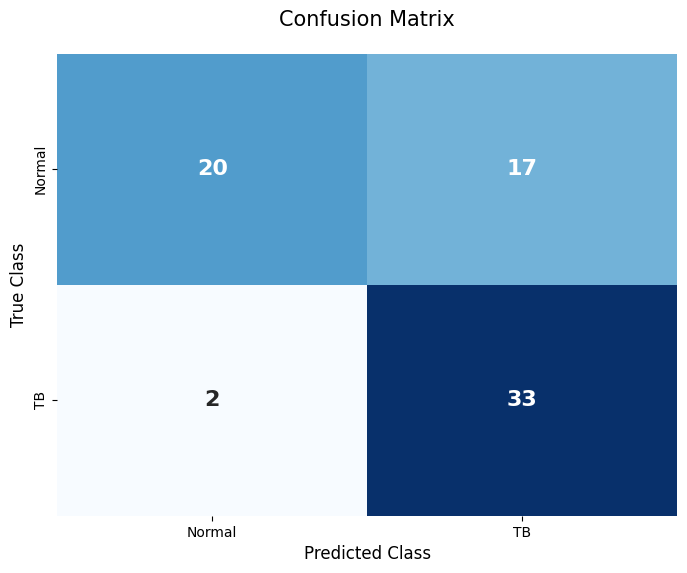

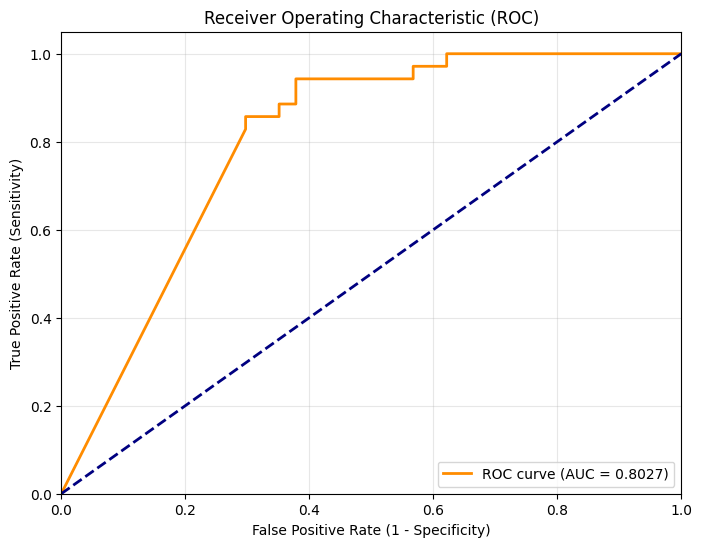

In [47]:
## DATASET

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

transforms = T.Compose([
    # T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean = mean, std = mean)
])

test_td = ImageFolder(root = './test', transform = transforms)
test_dl = DataLoader(test_td, batch_size = 32)

path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
PATH = os.path.join(path_classification, 'custom_class_seg_noaug_sa.pt')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = torch.load(PATH, map_location = device, weights_only=False)

predictions, probs, labels = model_predict_new(model, test_dl, device)

### run 2_0 (SA + aug)

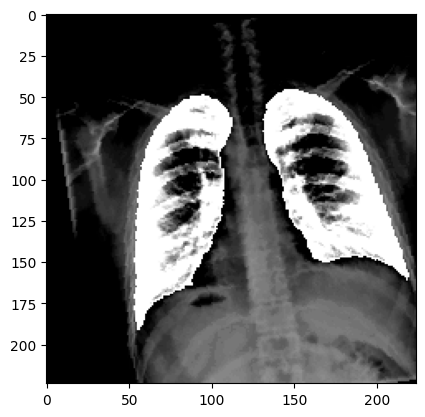

In [51]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt
import numpy as np

# TRANSFORMS

transforms = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)      # <--- normalization added
])

# TENSOR DATASETS
train_td = ImageFolder(root = './train', transform = T.Compose([
    T.RandomHorizontalFlip(p = 0.5),
    T.RandomAffine(degrees = 10, #patient is not always straight
                       translate = (0.1, 0.1), #shift it vertically and horizontally from the center
                       scale = (0.9, 1.1)), # controls the size of the lungs
    T.ColorJitter(brightness = 0.1, contrast = 0.1),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)      # <--- normalization added
])
)

val_td = ImageFolder(root = './val', transform = transforms)
test_td = ImageFolder(root = './test', transform = transforms)

# TO BATCHES
train_dl = DataLoader(train_td, batch_size = 32, shuffle = True)
val_dl = DataLoader(val_td, batch_size = 32)
test_dl = DataLoader(test_td, batch_size = 32)

plt.imshow(train_td[0][0].permute(1, 2, 0));

Best model saved at epoch 1
Epoch: [1/50]	 Train Loss: 0.76	    Val Loss: 0.70	 Train Acc: 0.50	 Val Acc: 0.51    Train Time: 0.07	 Val Time: 0.01
Best model saved at epoch 2
Epoch: [2/50]	 Train Loss: 0.69	    Val Loss: 0.70	 Train Acc: 0.51	 Val Acc: 0.51    Train Time: 0.06	 Val Time: 0.01
Best model saved at epoch 3
Epoch: [3/50]	 Train Loss: 0.69	    Val Loss: 0.70	 Train Acc: 0.51	 Val Acc: 0.51    Train Time: 0.08	 Val Time: 0.01
Best model saved at epoch 4
Epoch: [4/50]	 Train Loss: 0.69	    Val Loss: 0.70	 Train Acc: 0.51	 Val Acc: 0.51    Train Time: 0.06	 Val Time: 0.01
Best model saved at epoch 5
Epoch: [5/50]	 Train Loss: 0.69	    Val Loss: 0.70	 Train Acc: 0.51	 Val Acc: 0.51    Train Time: 0.06	 Val Time: 0.01
Best model saved at epoch 6
Epoch: [6/50]	 Train Loss: 0.69	    Val Loss: 0.70	 Train Acc: 0.51	 Val Acc: 0.51    Train Time: 0.08	 Val Time: 0.01
Best model saved at epoch 7
Epoch: [7/50]	 Train Loss: 0.69	    Val Loss: 0.70	 Train Acc: 0.51	 Val Acc: 0.51    Trai

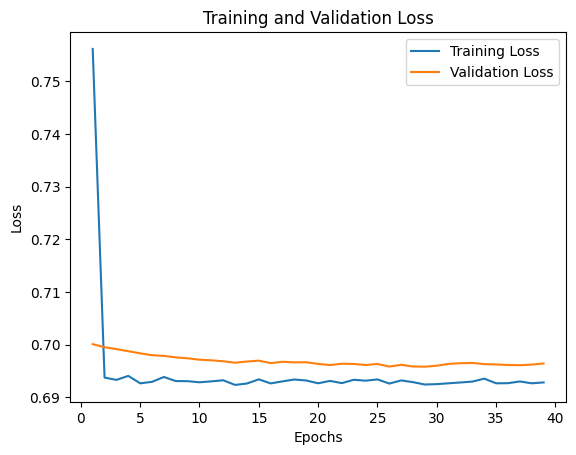

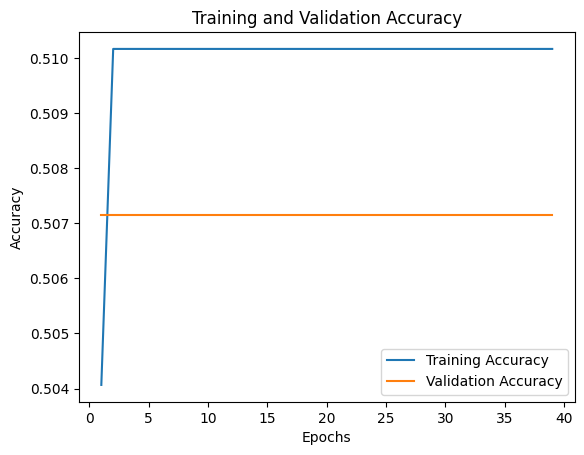

Training time : 2.64
Validation time : 0.37


In [52]:
# MODEL

class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()


# TRAINING

# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001, betas = (0.9, 0.99))

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
save_path = os.path.join(path_classification, 'custom_class_seg_aug_sa.pt')

history_train = model_train_save_es(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 50, patience = 10, device = device
)

#plot
plot_results_new(history_train)

# total time taken for training and validation
print(f"Training time : {sum(history_train['Training']['Time']):.2f}")
print(f"Validation time : {sum(history_train['Validation']['Time']):.2f}")

#### Load and Predict

Prediction Metrics
Test Accuracy: 0.5139 | f1: 0.0000 | AUC: 0.5000
Sensitivity: 0.0000 | Specificity: 1.0000
Precision: 0.0000| Test Time: 0.0057


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


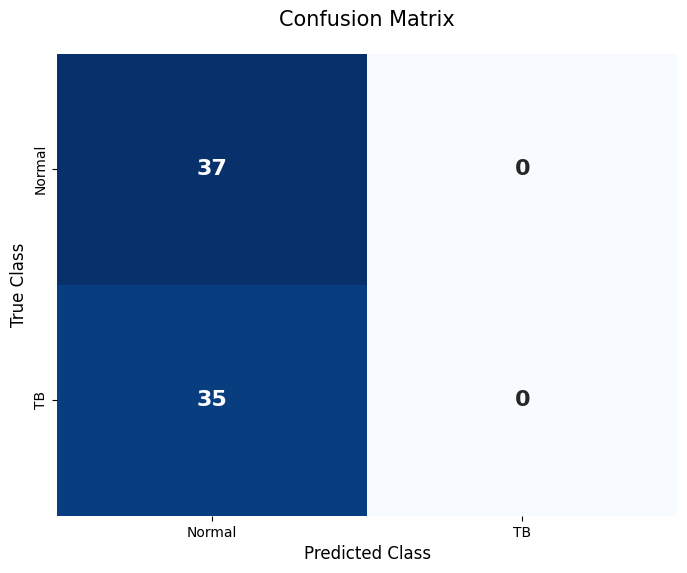

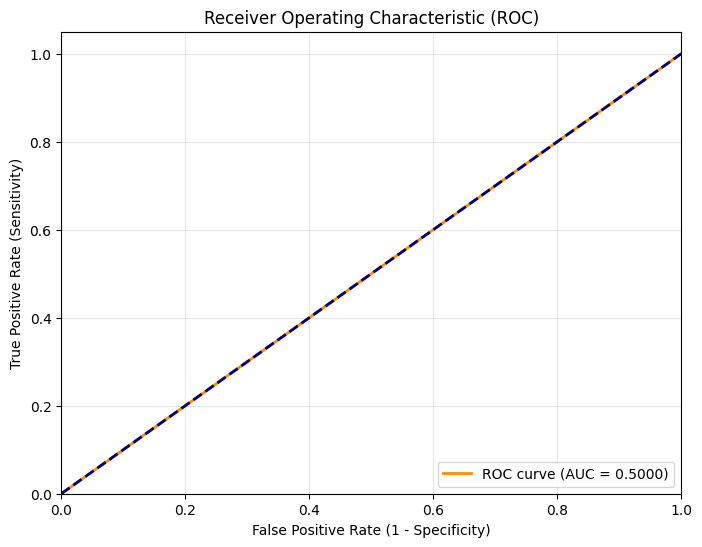

In [53]:
## DATASET

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

transforms = T.Compose([
    # T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean = mean, std = std)
])

test_td = ImageFolder(root = './test', transform = transforms)
test_dl = DataLoader(test_td, batch_size = 32)

path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
PATH = os.path.join(path_classification, 'custom_class_seg_aug_sa.pt')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = torch.load(PATH, map_location = device, weights_only=False)

predictions, probs, labels = model_predict_new(model, test_dl, device)

# SEGMENT 4200

In [ ]:
path_segmentation = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/segmentation'

### Dataset downloading




In [ ]:
## Download data

import kagglehub

# Download latest version
path_rahman = kagglehub.dataset_download("tawsifurrahman/tuberculosis-tb-chest-xray-dataset")

print("Path to dataset files:", path_rahman)

100%|██████████| 663M/663M [00:03<00:00, 190MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/tawsifurrahman/tuberculosis-tb-chest-xray-dataset/versions/3



# of TB images: 700
# of Normal images: 3500
Total: 4200
Train set #: 3360
Validation set #: 420
Test set #: 420
Total: 4200
Successfuly created Images Directory


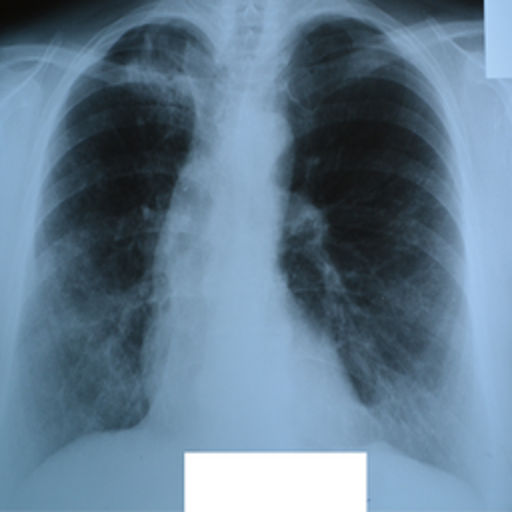

In [ ]:
import os
import pandas as pd
import PIL
import shutil # Added shutil here as it's used later in the function

def create_images_folder_4200(path):

  tb_md = pd.read_excel(os.path.join(path,'TB_Chest_Radiography_Database', 'Tuberculosis.metadata.xlsx'))
  # display(tb_md.head())
  # display(tb_md.info())

  no_tb_md = pd.read_excel(os.path.join(path,'TB_Chest_Radiography_Database', 'Normal.metadata.xlsx'))
  # display(no_tb_md.head())
  # display(no_tb_md.info())


  # Get the ids of the images corr to TB and no-TB
  img_id1 = list(tb_md['FILE NAME'])
  img_id0 = list(no_tb_md['FILE NAME'])

  print()
  print(f'# of TB images: {len(img_id1)}')
  print(f'# of Normal images: {len(img_id0)}')
  print(f'Total: {len(img_id1) + len(img_id0)}')

  # We will split train, validation and test set using 70%, 20% and 10%.
  # We will consider these ratios at the class level since we want every set
  # have a balanced number of images wrt the classes.

  train_ratio = 0.8
  val_ratio = 0.1
  test_ratio = 0.1

  # int uses floor, so the test set will have a couple more images than intended
  # This is stratified sampling
  train_no_1 = int(train_ratio * len(img_id1))
  train_no_0 = int(train_ratio * len(img_id0))
  # print(f'Train: {train_no_1} + {train_no_0} = {train_no_1 + train_no_0}')

  val_no_1 = int(val_ratio * len(img_id1))
  val_no_0 = int(val_ratio * len(img_id0))
  # print(f'Validation: {val_no_1} + {val_no_0} = {val_no_1 + val_no_0}')

  test_no_1 = int(test_ratio * len(img_id1))
  test_no_0 = int(test_ratio * len(img_id0))
  # print(f'Test: {test_no_1} + {test_no_0} = {test_no_1 + test_no_0}')

  # split
  train_1 = img_id1[:train_no_1]
  train_0 = img_id0[:train_no_0]
  train = train_1 + train_0
  print(f'Train set #: {len(train)}')

  val_1 = img_id1[train_no_1:train_no_1 + val_no_1]
  val_0 = img_id0[train_no_0:train_no_0 + val_no_0]
  val = val_1 + val_0
  print(f'Validation set #: {len(val)}')

  test_1 = img_id1[train_no_1 + val_no_1:]
  test_0 = img_id0[train_no_0 + val_no_0:]
  test = test_1 + test_0
  print(f'Test set #: {len(test)}')

  print(f'Total: {len(train) + len(val) + len(test)}')

  ## set up directories

  # Removed redundant import os and import shutil here

  sets = ['Images']
  klases = ['tb', 'no_tb']

  current_path = os.getcwd()

  # train_dir = os.makedirs(os.path.join(current_path, sets[0]))
  # val_dir = os.makedirs(os.path.join(current_path, sets[1]))
  # test_dir = os.makedirs(os.path.join(current_path, sets[2]))

  for s in sets:
      for klas in klases:
        if not os.path.exists(os.path.join(current_path, s, klas)):
          os.makedirs(os.path.join(current_path, s, klas))

  path_tb_images = os.path.join(path, 'TB_Chest_Radiography_Database', 'Tuberculosis')
  path_no_tb_images = os.path.join(path, 'TB_Chest_Radiography_Database', 'Normal')


  # copying from the image path to set up directories

    # TB Images
  for i in img_id1:
    str_i = str(i) + '.png' #convert id into image id string
    shutil.copy(src = os.path.join(path_tb_images,str_i), dst = os.path.join(current_path,'Images/tb'))

  # No TB Images
  for i in img_id0:
    str_i = str(i) + '.png' #convert id into image id string
    shutil.copy(src = os.path.join(path_no_tb_images,str_i), dst = os.path.join(current_path,'Images/no_tb'))

  print (f'Successfuly created Images Directory')

  return img_id1, img_id0


# create
img_id1, img_id0 = create_images_folder_4200(path_rahman)

# show image
path_image = './Images/tb/Tuberculosis-1.png'
PIL.Image.open(path_image)

### Load model for segmentation

In [ ]:
from torchvision.models import vgg16_bn
import torch.nn as nn


# CONV AND UP_CONV LAYERS
def conv(in_channels, out_channels):
  return nn.Sequential(
      nn.Conv2d(in_channels, out_channels, kernel_size = 3, stride=1, padding = 1),
      nn.BatchNorm2d(out_channels),
      nn.ReLU(inplace=True)
  )

def up_conv(in_channels, out_channels):
  return nn.Sequential(
      nn.ConvTranspose2d(in_channels, out_channels, kernel_size = 2, stride = 2),
      nn.BatchNorm2d(out_channels),
      nn.ReLU(inplace=True)
  )


# UNET CLASS
class UNet(nn.Module):

  def __init__(self, num_classes = 2):
    super().__init__()

    self.encoder = vgg16_bn(weights = 'DEFAULT').features

    self.block1 = nn.Sequential(*self.encoder[:6])
    self.block2 = nn.Sequential(*self.encoder[6:13])
    self.block3 = nn.Sequential(*self.encoder[13:20])
    self.block4 = nn.Sequential(*self.encoder[20:27])
    self.block5 = nn.Sequential(*self.encoder[27:34])

    self.bottleneck = nn.Sequential(*self.encoder[34:])
    self.conv_bottleneck = conv(512, 1024) #increase channels. prepare for upsampling

    self.up_conv6 = up_conv(1024, 512)
    self.conv6 = conv(512 + 512, 512)
    self.up_conv7 = up_conv(512, 256)
    self.conv7 = conv(256 + 512, 256)
    self.up_conv8 = up_conv(256, 128)
    self.conv8 = conv(128 + 256, 128)
    self.up_conv9 = up_conv(128, 64)
    self.conv9 = conv(64 + 128, 64)
    self.up_conv10 = up_conv(64, 32)
    self.conv10 = conv(32 + 64, 32)

    self.conv11 = nn.Conv2d(32, num_classes, kernel_size = 1)

  def forward(self, x):

    # input is (3, 224, 224)
    # output is (64, 224, 224)
    block1 = self.block1(x)

    #output is (128, 112, 112)
    block2 = self.block2(block1)

    #output (256, 56, 56)
    block3 = self.block3(block2)

    #output (512, 28, 28)
    block4 = self.block4(block3)

    #output (512, 14, 14)
    block5 = self.block5(block4)

    #output (512, 7, 7)
    bottleneck = self.bottleneck(block5)

    #ouput (1024, 7, 7)
    x = self.conv_bottleneck(bottleneck)

    # output is (512, 14, 14)
    x = self.up_conv6(x)
    # output (512 + 512, 14, 14)
    x = torch.cat([x, block5], dim = 1) # we concatenate along the channels (i.e stack the features)
    # output is (512, 14, 14)
    x = self.conv6(x)

    # output (256, 28, 28)
    x = self.up_conv7(x)

    # output (256 + 512, 28, 28)
    x = torch.cat([x, block4], dim = 1)
    # output (256, 28, 28)
    x = self.conv7(x)

    # output (128, 56, 56)
    x = self.up_conv8(x)
    # output (128 + 256, 56, 56)
    x = torch.cat([x, block3], dim = 1)
    # output (128, 56, 56)
    x = self.conv8(x)

    # output (64, 112, 112)
    x = self.up_conv9(x)
    # output (64 + 128, 112, 112)
    x = torch.cat([x, block2], dim = 1)
    # output (64, 112, 112)
    x = self.conv9(x)

    # output (64, 224, 224)
    x = self.up_conv10(x)
    # output (64 + 64, 224, 224)
    x = torch.cat([x, block1], dim = 1)
    # output (32, 224, 224)
    x = self.conv10(x)

    # output (n_classes, 224, 224)
    x = self.conv11(x)

    return x

import os
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model_path = os.path.join(path_segmentation, 'seg_unet_2.pth')
model = UNet()

model.load_state_dict(torch.load(model_path, map_location = device))

model.to(device)

UNet(
  (encoder): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(128, 256

### Prepare Data

Number of batches: 66
Number of Images: 4200


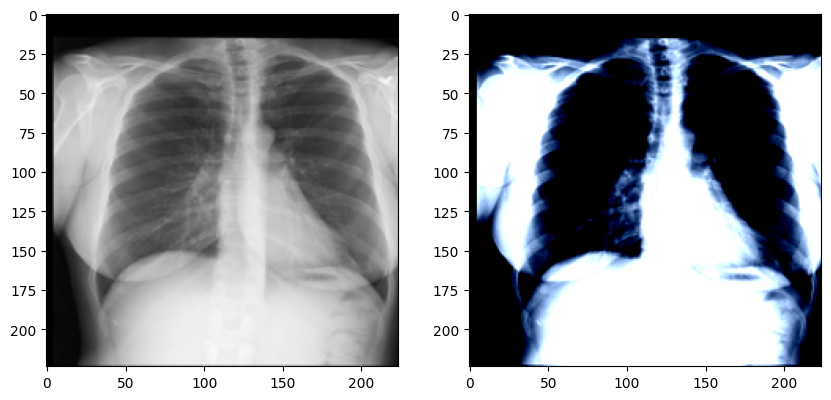

In [ ]:
import torch
from torch.utils.data import Dataset
from torchvision.transforms import v2 as T
import os
import PIL


class ROI(Dataset):

  ''' Returns an tensor object that can be batched for segmentation inference'''

  def __init__(self, root_dir):

    # transforms used in the segmentation model for eval, not training

    self.transforms_norm = T.Compose([
        T.Resize((224, 224)),
        T.ToImage(), #converts a PIL Image to tv2_tensor
        T.ToDtype(torch.float32, scale = True), # scales
        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])

    self.transforms_orig = T.Compose([
        T.Resize((224, 224)),
        T.ToImage(), #converts a PIL Image to tv2_tensor
        T.ToDtype(torch.float32, scale = True),
    ])

    # directory with Images
    self.root_dir = root_dir

    # sub-directories
    im_id0 = os.listdir (os.path.join(self.root_dir, 'no_tb'))
    im_id1 = os.listdir (os.path.join(self.root_dir, 'tb'))

    # add a tag of 0 and 1 for labelling later
    # im_id0_tag = ['0_' + im for im in im_id0]
    # im_id1_tag = ['1_' + im for im in im_id1]

    # a full list with tagged image names
    # self.im_ls = im_id0_tag + im_id1_tag

    # GEMINI clean GENIUS
    self.im_data = []

    for f in im_id0:
      self.im_data.append(('no_tb', f, 0))

    for f in im_id1:
      self.im_data.append(('tb', f, 1))

  def __len__(self):
    return len(self.im_data)


  def __getitem__(self, idx):

    # if self.im_ls[idx].startswith('0_'):
    #   label = torch.tensor(0).long()
    # else:
    #   label = torch.tensor(1).long()

    # we start from index 2 since that is where the actual image name is found.
    # im_path = os.path.join(self.root_dir, self.im_ls[idx][2:])

    im_path = os.path.join(self.root_dir, self.im_data[idx][0], self.im_data[idx][1])
    label = torch.tensor(self.im_data[idx][2]).long()

    # get the name. will be useful for saving in the inference loop
    im_name = self.im_data[idx][1]


    image = PIL.Image.open(im_path).convert('RGB')

    image_orig = self.transforms_orig(image)

    image_norm = self.transforms_norm(image)

    return image_orig, image_norm, label, im_name

# tensor dataset
td = ROI('./Images')

# confirm images display
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize = (10, 10))

ax[0].imshow(td[0][0].permute(1, 2, 0))
ax[1].imshow(td[0][1].permute(1, 2, 0))

# data loader
dl = DataLoader (td, batch_size = 64)

# Number of batches and images
print (f'Number of batches: {len(dl)}')

# Number of images
print (f'Number of Images: {len(dl.dataset)}')


### Inference

In [ ]:
from torchvision.utils import save_image
import os
import torch
import time

def segmentation_inference(model, data_loader, device, roi_dir):

  model.to(device)
  model.eval()

  # make directories if non_existent
  os.makedirs(os.path.join(roi_dir, 'tb'), exist_ok=True)
  os.makedirs(os.path.join(roi_dir, 'no_tb'), exist_ok=True)

  print(f"Starting inference. Saving images to {roi_dir}...")

  start_time = time.time()  # Start the clock

  with torch.no_grad():
    for batch_idx, batch in enumerate(data_loader):

      images_orig = batch[0].to(device)
      images_norm = batch[1].to(device)
      label_batch = batch[2]
      img_name_batch = batch[3]

      # Inference
      masks = model(images_norm)
      pred_masks = masks.argmax(dim=1)
      roi_batch = images_orig * pred_masks.unsqueeze(1)

      # Save Loop
      for i in range(len(roi_batch)):
        img = roi_batch[i]
        img_name = img_name_batch[i]
        folder = 'tb' if label_batch[i].item() == 1 else 'no_tb'

        save_image(img, os.path.join(roi_dir, folder, img_name), normalize=True)

      # --- PROGRESS UPDATE (Inside the Loop) ---
      if (batch_idx + 1) % 5 == 0:
        current_time = time.time()
        elapsed_mins = (current_time - start_time) / 60
        print(f'Finished batch {batch_idx + 1}. Time elapsed: {elapsed_mins:.2f} min')

  # --- FINAL TIME (Outside the Loop) ---
  end_time = time.time()
  total_time = (end_time - start_time) / 60
  print(f'Done! Total Inference time: {total_time:.2f} minutes')

# Usage
segmentation_inference(model, dl, device, './ROI_Images')

Starting inference. Saving images to ./ROI_Images...
Finished batch 5. Time elapsed: 0.19 min
Finished batch 10. Time elapsed: 0.37 min
Finished batch 15. Time elapsed: 0.53 min
Finished batch 20. Time elapsed: 0.74 min
Finished batch 25. Time elapsed: 0.92 min
Finished batch 30. Time elapsed: 1.09 min
Finished batch 35. Time elapsed: 1.25 min
Finished batch 40. Time elapsed: 1.44 min
Finished batch 45. Time elapsed: 1.63 min
Finished batch 50. Time elapsed: 1.82 min
Finished batch 55. Time elapsed: 1.99 min
Finished batch 60. Time elapsed: 2.18 min
Finished batch 65. Time elapsed: 2.36 min
Done! Total Inference time: 2.38 minutes


### Check ROI Image

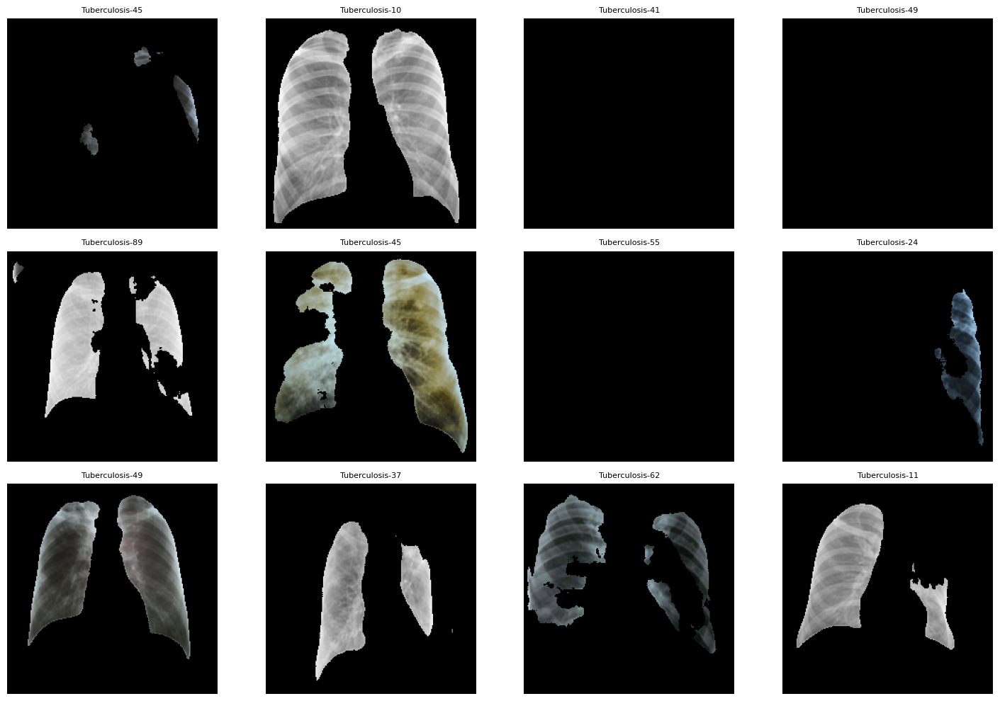

In [ ]:
import os
import PIL
import matplotlib.pyplot as plt

# Get a list of images in the 'tb' subfolder
roi_tb_path = './ROI_Images/tb'
roi_tb_images = os.listdir(roi_tb_path)

# Check if we have images
if roi_tb_images:

    # Select the first 12 images (or fewer if less than 12 exist)
    num_images = 12
    sample_images = roi_tb_images[:num_images]

    # Create a figure with a grid of 3 rows x 4 columns
    fig, axes = plt.subplots(3, 4, figsize=(15, 10))
    axes = axes.flatten() # Flatten the 2D grid into a 1D list for easier looping

    for i, ax in enumerate(axes):
        if i < len(sample_images):
            # Get image path
            img_name = sample_images[i]
            img_path = os.path.join(roi_tb_path, img_name)

            # Open and display
            img = PIL.Image.open(img_path)
            ax.imshow(img, cmap='gray')
            ax.set_title(img_name[:15], fontsize=8) # truncated title for neatness
            ax.axis('off')
        else:
            # Hide unused subplots if there are fewer than 12 images
            ax.axis('off')

    plt.tight_layout()
    plt.show()

else:
    print("No images found in ./ROI_Images/tb.")

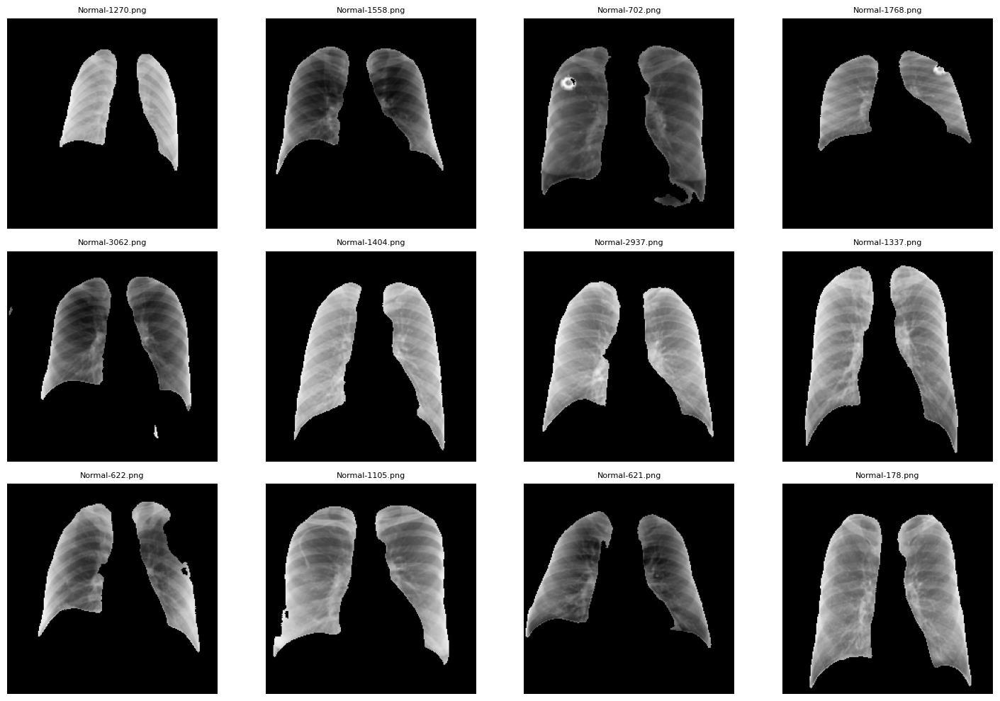

In [ ]:
import os
import PIL
import matplotlib.pyplot as plt

# Get a list of images in the 'tb' subfolder
roi_tb_path = './ROI_Images/no_tb'
roi_tb_images = os.listdir(roi_tb_path) # healthy images

# Check if we have images
if roi_tb_images:

    # Select the first 12 images (or fewer if less than 12 exist)
    num_images = 12
    sample_images = roi_tb_images[:num_images]

    # Create a figure with a grid of 3 rows x 4 columns
    fig, axes = plt.subplots(3, 4, figsize=(15, 10))
    axes = axes.flatten() # Flatten the 2D grid into a 1D list for easier looping

    for i, ax in enumerate(axes):
        if i < len(sample_images):
            # Get image path
            img_name = sample_images[i]
            img_path = os.path.join(roi_tb_path, img_name)

            # Open and display
            img = PIL.Image.open(img_path)
            ax.imshow(img, cmap='gray')
            ax.set_title(img_name[:15], fontsize=8) # truncated title for neatness
            ax.axis('off')
        else:
            # Hide unused subplots if there are fewer than 12 images
            ax.axis('off')

    plt.tight_layout()
    plt.show()

else:
    print("No images found in ./ROI_Images/tb.")

# CLASSIFICATION SEG DATA 4200

In [ ]:
def setup_roi_database_4200(path):

  '''Set up of the ROI Images database to use for classification. The target is
  to just use ImageFolder for the tensor dataset and data loader.

  path is the folder where the images are''' #there was sth causing syntax warning

  import os
  import pandas as pd

  roi_0 = os.listdir(os.path.join(path, 'no_tb'))
  roi_1 = os.listdir(os.path.join(path, 'tb'))

  print('Splitting Details')
  print(f'# of TB images: {len(roi_1)}')
  print(f'# of Normal images: {len(roi_0)}')
  print(f'Total: {len(roi_1) + len(roi_0)}')

  # We will split train, validation and test set using 70%, 20% and 10%.
  # We will consider these ratios at the class level since we want every set
  # have a balanced number of images wrt the classes.

  train_ratio = 0.7
  val_ratio = 0.2
  test_ratio = 0.1

  # int uses floor, so the test set will have a couple more images than intended
  train_no_1 = int(train_ratio * len(roi_1))
  train_no_0 = int(train_ratio * len(roi_0))
  # print(f'Train: {train_no_1} + {train_no_0} = {train_no_1 + train_no_0}')

  val_no_1 = int(val_ratio * len(roi_1))
  val_no_0 = int(val_ratio * len(roi_0))
  # print(f'Validation: {val_no_1} + {val_no_0} = {val_no_1 + val_no_0}')

  test_no_1 = int(test_ratio * len(roi_1))
  test_no_0 = int(test_ratio * len(roi_0))
  # print(f'Test: {test_no_1} + {test_no_0} = {test_no_1 + test_no_0}')

  # split
  train_1 = roi_1[:train_no_1]
  train_0 = roi_0[:train_no_0]
  train = train_1 + train_0
  print(f'Train set #: {len(train)}')

  val_1 = roi_1[train_no_1:train_no_1 + val_no_1]
  val_0 = roi_0[train_no_0:train_no_0 + val_no_0]
  val = val_1 + val_0
  print(f'Validation set #: {len(val)}')

  test_1 = roi_1[train_no_1 + val_no_1:]
  test_0 = roi_0[train_no_0 + val_no_0:]
  test = test_1 + test_0
  print(f'Test set #: {len(test)}')

  print(f'Total: {len(train) + len(val) + len(test)}')
  print()


  ## set up directories

  print ('Setting up directories..')
  import os
  import shutil

  sets = ['train', 'val', 'test']
  klases = ['tb', 'no_tb']

  current_path = os.getcwd()

  for s in sets:
    for klas in klases:
      os.makedirs(os.path.join(current_path, s, klas), exist_ok = True)

  # copying from the image path to set up directories. code is really repetitive and bad, but it works!

  #train
  for i in train_1:
    shutil.copy(src = os.path.join(path,'tb', i), dst = os.path.join(current_path,'train','tb'))

  for i in train_0:
    shutil.copy(src = os.path.join(path,'no_tb', i), dst = os.path.join(current_path,'train','no_tb'))

  # val
  for i in val_1:
    shutil.copy(src = os.path.join(path,'tb', i), dst = os.path.join(current_path,'val','tb'))

  for i in val_0:
    shutil.copy(src = os.path.join(path,'no_tb', i), dst = os.path.join(current_path,'val','no_tb'))

  #test
  for i in test_1:
    shutil.copy(src = os.path.join(path,'tb', i), dst = os.path.join(current_path,'test','tb'))

  for i in test_0:
    shutil.copy(src = os.path.join(path,'no_tb', i), dst = os.path.join(current_path,'test','no_tb'))

setup_roi_database_4200('./ROI_Images')

Splitting Details
# of TB images: 700
# of Normal images: 3500
Total: 4200
Train set #: 2939
Validation set #: 840
Test set #: 421
Total: 4200

Setting up directories..


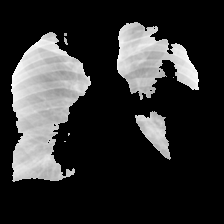

In [ ]:
import PIL

path_image = os.path.join('./train', 'tb', 'Tuberculosis-10.png')
PIL.Image.open(path_image)

### Dataset Preparation

In [ ]:
## DATASET

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

# from torchview import draw_graph

transforms = T.Compose([
    # T.Resize((224, 224)),
    T.ToTensor(),
    # T.Normalize(mean = [0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225] )
])

train_td = ImageFolder(root = './train', transform = T.Compose([
    # T.Resize((224, 224)),
    # T.RandomHorizontalFlip(p = 0.5),
    T.ToTensor(),
    # T.Normalize(mean = [0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225] )

])
)

val_td = ImageFolder(root = './val', transform = transforms)
test_td = ImageFolder(root = './test', transform = transforms)

train_dl = DataLoader(train_td, batch_size = 32, shuffle = True)
val_dl = DataLoader(val_td, batch_size = 32)
test_dl = DataLoader(test_td, batch_size = 32)

print (f'Number of batches in train: {len(train_dl)}')
print (f'Number of batches in val: {len(val_dl)}')
print (f'Number of batches in test: {len(test_dl)}')

print (f'Total Images: {len(train_dl.dataset) + len (test_dl.dataset) + len (val_dl.dataset)}')

Number of batches in train: 92
Number of batches in val: 27
Number of batches in test: 14
Total Images: 4200


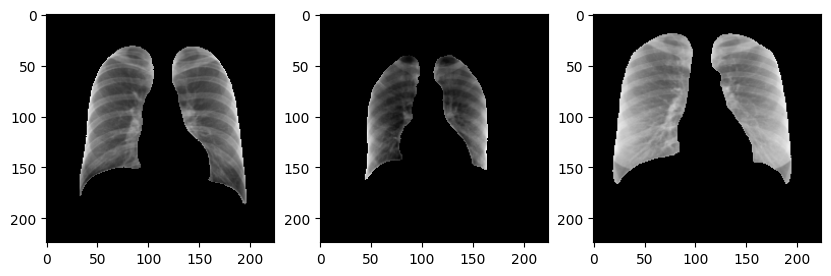

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize = (10, 10))

ax[0].imshow(train_td[0][0].permute(1, 2, 0))
ax[1].imshow(test_td[1][0].permute(1, 2, 0))
ax[2].imshow(val_td[2][0].permute(1, 2, 0))

### run 1

In [ ]:
class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

# model_graph = draw_graph(model, input_size=(1, 3, 224, 224),
#                          expand_nested=True,
#                          hide_inner_tensors=True,
#                          hide_module_functions=True
#                          )

# model_graph.visual_graph

print(model)

CNN(
  (layers): Sequential(
    (0): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Dropout(p=0.3, inplace=False)
    (4): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1))
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.5, inplace=False)
    (8): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (9): ReLU()
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Dropout(p=0.5, inplace=False)
    (12): Flatten(start_dim=1, end_dim=-1)
    (13): Linear(in_features=43264, out_features=16, bias=True)
    (14): ReLU()
    (15): Dropout(p=0.2, inplace=False)
    (16): Linear(in_features=16, out_features=2, bias=True)
  )
)


Best model saved at epoch 1
Epoch: [1/100]	 Train Loss: 0.37	    Val Loss: 0.29	 Train Acc: 0.86	 Val Acc: 0.95    Train Time: 0.31	 Val Time: 0.05
Best model saved at epoch 2
Epoch: [2/100]	 Train Loss: 0.23	    Val Loss: 0.25	 Train Acc: 0.93	 Val Acc: 0.94    Train Time: 0.30	 Val Time: 0.04
Best model saved at epoch 3
Epoch: [3/100]	 Train Loss: 0.22	    Val Loss: 0.24	 Train Acc: 0.93	 Val Acc: 0.94    Train Time: 0.29	 Val Time: 0.04
Epoch: [4/100]	 Train Loss: 0.22	    Val Loss: 0.28	 Train Acc: 0.94	 Val Acc: 0.92    Train Time: 0.30	 Val Time: 0.06
Epoch: [5/100]	 Train Loss: 0.19	    Val Loss: 0.25	 Train Acc: 0.94	 Val Acc: 0.92    Train Time: 0.36	 Val Time: 0.06
Epoch: [6/100]	 Train Loss: 0.19	    Val Loss: 0.25	 Train Acc: 0.94	 Val Acc: 0.92    Train Time: 0.31	 Val Time: 0.05
Best model saved at epoch 7
Epoch: [7/100]	 Train Loss: 0.19	    Val Loss: 0.23	 Train Acc: 0.94	 Val Acc: 0.93    Train Time: 0.28	 Val Time: 0.04
Best model saved at epoch 8
Epoch: [8/100]	 Trai

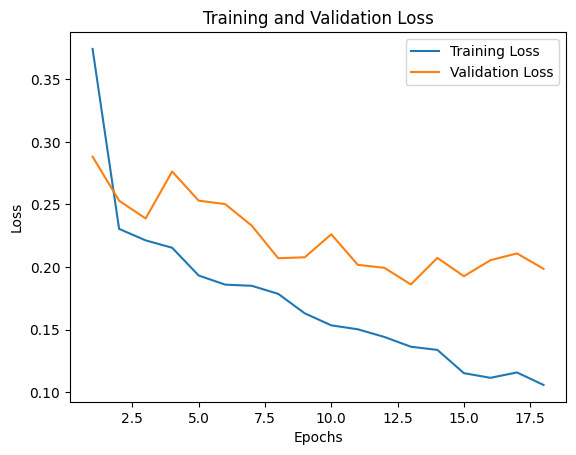

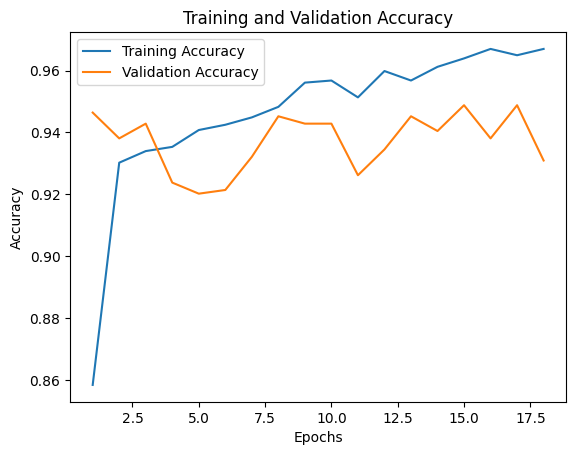

Training time : 5.27
Validation time : 0.84


In [ ]:
# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
save_path = os.path.join(path_classification, 'class_seg_3cnn_4200.pt')

history = model_train_save_es(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 100, patience = 5, device = device
)

#plot
plot_results_new(history)

# total time taken for training and validation
print(f"Training time : {sum(history['Training']['Time']):.2f}")
print(f"Validation time : {sum(history['Validation']['Time']):.2f}")

### Load and Evaluate

Prediction Metrics
Test Accuracy: 0.9311 | f1: 0.7914 | AUC: 0.9649
Sensitivity: 0.7746 | Specificity: 0.9629
Precision: 0.8088| Test Time: 0.0210


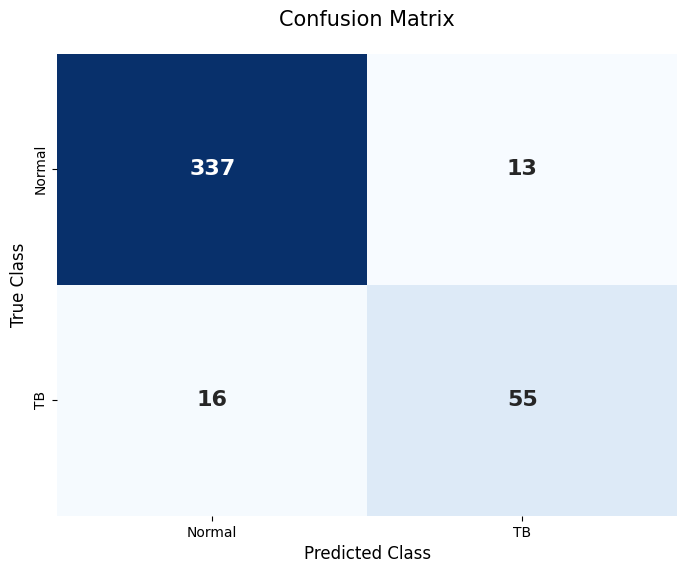

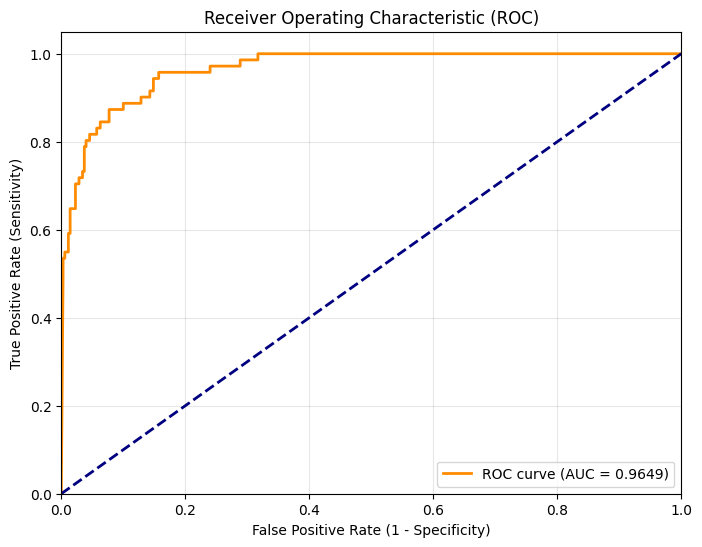

In [ ]:
## DATASET

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

transforms = T.Compose([
    # T.Resize((224, 224)),
    T.ToTensor(),
    # T.Normalize(mean = [0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225])
])

test_td = ImageFolder(root = './test', transform = transforms)
test_dl = DataLoader(test_td, batch_size = 32)

path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
PATH = os.path.join(path_classification, 'class_seg_3cnn_4200.pt')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = torch.load(PATH, map_location = device, weights_only=False)

predictions, probs, labels = model_predict_new(model, test_dl, device)

## grad-CAM

### no_tb

Using target layer: Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
Classes: ['no_tb', 'tb']
Selected 8 images for Grad‑CAM.


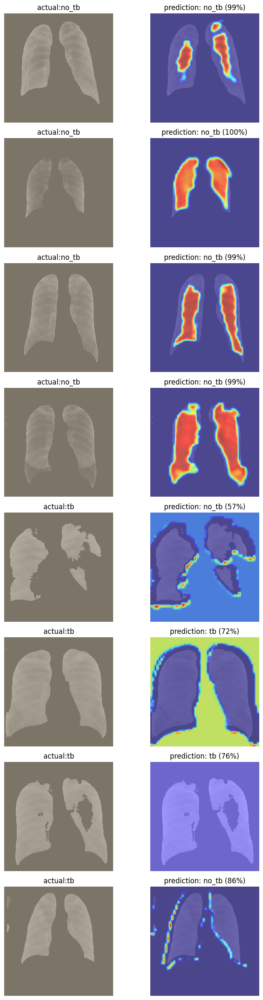

In [ ]:
import os
import random
import torch
import torch.nn as nn
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


# -------------------- CONFIGURATION --------------------
path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
PATH = os.path.join(path_classification, 'class_seg_3cnn_4200.pt')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = torch.load(PATH, weights_only=False)
model.to(device)

# unfreeze feature extraction layers to allow gradients flow
for param in model.parameters():
    param.requires_grad = True

model.eval()

data_dir = './test'
num_images_per_class = 4
image_size = (224, 224)

# -------------------- NORMALIZATION PARAMETERS --------------------

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# -------------------- FIND LAST CONV LAYER --------------------
def find_last_conv_layer(model):
    last_conv = None
    for name, module in model.named_modules():
        if isinstance(module, nn.Conv2d):
            last_conv = module
    if last_conv is None:
        raise ValueError("No convolutional layer found in the model.")
    return last_conv

target_layer = find_last_conv_layer(model)
print(f"Using target layer: {target_layer}")

# -------------------- PREPARE DATA --------------------
dataset = ImageFolder(root=data_dir, transform=None)
class_names = dataset.classes
print(f"Classes: {class_names}")

# Build a list of image paths per class
paths_per_class = {cls: [] for cls in class_names}
for path, label in dataset.samples:
    cls = class_names[label]
    paths_per_class[cls].append(path)

# Sort the paths for reproducibility and take the first N per class
selected_images = []
for cls in class_names:
    paths = paths_per_class[cls]
    # Sort paths alphabetically (by filename)
    paths.sort()
    selected = paths[:min(num_images_per_class, len(paths))]
    selected_images.extend([(cls, p) for p in selected])

print(f"Selected {len(selected_images)} images for Grad‑CAM.")

# -------------------- TRANSFORM (WITH NORMALIZATION) --------------------
val_transforms = T.Compose([
    T.Resize(image_size),
    T.ToTensor(),
    # T.Normalize(mean=mean, std=std)      # <--- normalization added
])

target_class = 0

# -------------------- GRAD-CAM LOOP --------------------
cam = GradCAM(model=model, target_layers=[target_layer])

fig, axes = plt.subplots(len(selected_images), 2, figsize=(8, 3*len(selected_images)))
if len(selected_images) == 1:
    axes = axes.reshape(1, -1)

for i, (cls_name, img_path) in enumerate(selected_images):
    pil_img = Image.open(img_path).convert('RGB')
    input_tensor = val_transforms(pil_img).unsqueeze(0).to(device)

    # Get prediction and confidence
    with torch.no_grad():
        logits = model(input_tensor)
        probs = torch.softmax(logits, dim=1)          # convert to probabilities
        pred_class = logits.argmax(dim=1).item()
        pred_confidence = probs[0, pred_class].item()  # confidence for predicted class

    targets = [ClassifierOutputTarget(target_class)]   # fixed target for Grad-CAM

    # Generate Grad-CAM (unchanged)
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0, :]

    # Denormalize (unchanged)
    img_tensor = input_tensor.squeeze(0).cpu()
    mean_tensor = torch.tensor(mean).view(3,1,1)
    std_tensor = torch.tensor(std).view(3,1,1)
    img_denorm = img_tensor * std_tensor + mean_tensor
    img_denorm = img_denorm.clamp(0, 1)
    rgb_img = img_denorm.permute(1, 2, 0).numpy()

    # Overlay heatmap
    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    # Plot with confidence in title
    axes[i, 0].imshow(rgb_img)
    axes[i, 0].set_title(f"actual:{cls_name}")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(cam_image)
    axes[i, 1].set_title(
        f"prediction: {class_names[pred_class]} ({pred_confidence:.0%})"
    )
    axes[i, 1].axis('off')

plt.tight_layout()

# save path
# images_save_path = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/images'
# exact_path = os.path.join(images_save_path, 'vgg', 'vgg_gradcam_4200_0.png')

# plt.savefig(exact_path, dpi=300)
plt.show();

### tb

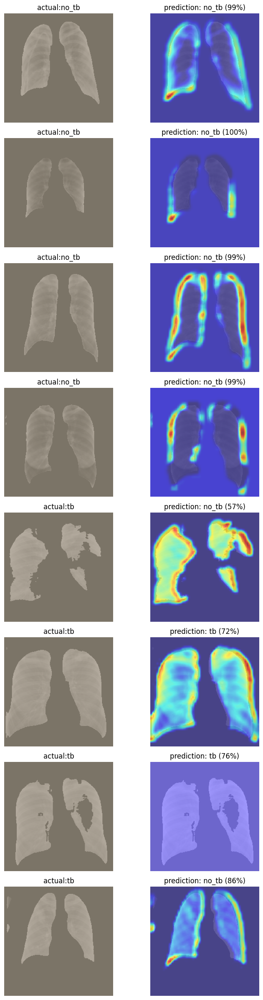

In [ ]:
target_class = 1

# -------------------- GRAD-CAM LOOP --------------------
cam = GradCAM(model=model, target_layers=[target_layer])

fig, axes = plt.subplots(len(selected_images), 2, figsize=(8, 3*len(selected_images)))
if len(selected_images) == 1:
    axes = axes.reshape(1, -1)

for i, (cls_name, img_path) in enumerate(selected_images):
    pil_img = Image.open(img_path).convert('RGB')
    input_tensor = val_transforms(pil_img).unsqueeze(0).to(device)

    # Get prediction and confidence
    with torch.no_grad():
        logits = model(input_tensor)
        probs = torch.softmax(logits, dim=1)          # convert to probabilities
        pred_class = logits.argmax(dim=1).item()
        pred_confidence = probs[0, pred_class].item()  # confidence for predicted class

    targets = [ClassifierOutputTarget(target_class)]   # fixed target for Grad-CAM

    # Generate Grad-CAM (unchanged)
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0, :]

    # Denormalize (unchanged)
    img_tensor = input_tensor.squeeze(0).cpu()
    mean_tensor = torch.tensor(mean).view(3,1,1)
    std_tensor = torch.tensor(std).view(3,1,1)
    img_denorm = img_tensor * std_tensor + mean_tensor
    img_denorm = img_denorm.clamp(0, 1)
    rgb_img = img_denorm.permute(1, 2, 0).numpy()

    # Overlay heatmap
    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    # Plot with confidence in title
    axes[i, 0].imshow(rgb_img)
    axes[i, 0].set_title(f"actual:{cls_name}")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(cam_image)
    axes[i, 1].set_title(
        f"prediction: {class_names[pred_class]} ({pred_confidence:.0%})"
    )
    axes[i, 1].axis('off')

plt.tight_layout()

# # save path
# images_save_path = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/images'
# exact_path = os.path.join(images_save_path, 'vgg', 'vgg_gradcam_4200_1.png')

# plt.savefig(exact_path, dpi=300)
plt.show();